In [1]:
import sys
import os
import math

from matplotlib import pyplot as plt
import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import TimeSeriesSplit, StratifiedKFold

import jax
import jax.numpy as jnp
import optax


sys.path.append(os.path.join(os.getcwd(), 'import'))

from utils import read_utils
from utils import plot_utils
from utils import train_utils
from utils import artificializer

from models import clm_sep as clm
from models import hgm_sep as hgm

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(artificializer)
importlib.reload(clm)
importlib.reload(hgm)

<module 'models.hgm_sep' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/Work/Workspaces/UNIVIE/JetBrains/DataSpell/MSc_Thesis/worm-2025-fieseler/import/models/hgm_sep.py'>

# Functions

In [3]:
def fit_analytical_model(splits, X, Y):
	model_per_split = list()
	neuron_score_per_split = list()
	loss_per_split = list()
	loss_tr_per_split = list()
	for train, test in splits:
		X_train, X_test = X[train], X[test]
		Y_train, Y_test = Y[train], Y[test]

		model = LinearRegression(fit_intercept=False)
		model.fit(X_train, Y_train)

		Y_pred = model.predict(X_test)
		loss = jnp.mean((Y_pred - Y_test) ** 2)  # mean. consider alternatives
		loss_tr = jnp.mean((model.predict(X_train) - Y_train) ** 2)
		score_per_neuron = [r2_score(trace, trace_pred) for trace, trace_pred in zip(Y_test.T, Y_pred.T)]

		model_per_split.append(model)
		neuron_score_per_split.append(np.array(score_per_neuron))
		loss_per_split.append(loss)
		loss_tr_per_split.append(loss_tr)

	return model_per_split, np.array(neuron_score_per_split), np.array(loss_per_split), np.array(loss_tr_per_split)

In [4]:
def fit_analytical_models(filenames, discrete_states, eigenworms, traces_residual):
	models_models_art = list()
	models_scores_art = list()
	models_losses_art = list()
	models_losses_tr_art = list()

	for i in range(len(filenames)):
		print(f'{i+1}/{len(filenames)}: {filenames[i]} ', end='')

		splits = list(StratifiedKFold(n_splits=5).split(np.zeros(eigenworms[i].values.shape[0]), discrete_states[i]['REV'].values))

		(model_per_split,
		 neuron_score_per_split,
		 loss_per_split,
		 loss_tr_per_split) = fit_analytical_model(splits,
												   eigenworms[i].values,
												   traces_residual[i].values)

		models_models_art.append(model_per_split)
		models_scores_art.append(neuron_score_per_split)
		models_losses_art.append(loss_per_split)
		models_losses_tr_art.append(loss_tr_per_split)

	return models_models_art, models_scores_art, models_losses_art, models_losses_tr_art

In [5]:
def train_numerical_model(model, splits, X_bll, Y, X_man=None, hyperparams=None):
	is_hgm = model.get_type()

	seeds = jax.random.PRNGKey(0), jax.random.PRNGKey(1)

	# Hyperparamters ============
	if hyperparams is None:
		hyperparams = {
			'max_epochs': 1000,
			'max_patience': 100,
			'learning_rate': 0.5,
			'w1_reg_lambda': 1E-3,
			'w2_reg_lambda': 1E-5,
		}

	max_epochs = hyperparams['max_epochs']
	max_patience = hyperparams['max_patience']

	optimizer = optax.adam(hyperparams['learning_rate'])

	reg_lambdas = hyperparams['w1_reg_lambda'], hyperparams['w2_reg_lambda']
	# ===========================

	n_neurons = Y.shape[1]
	n_behaviors_ll = X_bll.shape[1]
	if is_hgm: n_dimensions = X_man.shape[1]

	# training loop =======================================
	params_per_split = list()
	neuron_scores_per_split = list()
	losses_per_split = list()
	losses_tr_per_split = list()
	mse_losses_per_split = list()
	mse_losses_tr_per_split = list()
	__grads_per_split = list()
	for train, test in splits:
		# splitting and initializing ========================= (this also moves the data to the GPU)
		X_bll_train, X_bll_test = jnp.array(X_bll[train]), jnp.array(X_bll[test])
		if is_hgm: X_man_train, X_man_test = jnp.array(X_man[train]), jnp.array(X_man[test])
		Y_train, Y_test = jnp.array(Y[train]), jnp.array(Y[test])

		if is_hgm:
			params = model.init_params(seeds, (n_behaviors_ll, n_neurons), (n_dimensions, n_neurons))
		else:
			params = model.init_params(seeds, (n_behaviors_ll, n_neurons))
		opt_state = optimizer.init(params)
		# ==========================================================================================

		if is_hgm:
			losses = [model.loss_fn(params, X_bll_test, X_man_test, Y_test, reg_lambdas).item()]
			losses_tr = [model.loss_fn(params, X_bll_train, X_man_train, Y_train, reg_lambdas).item()]
			mse_losses = [model.mse_loss_fn(params, X_bll_test, X_man_test, Y_test).item()]
			mse_losses_tr = [model.mse_loss_fn(params, X_bll_train, X_man_train, Y_train).item()]
		else:
			losses = [model.loss_fn(params, X_bll_test, Y_test, reg_lambdas).item()]
			losses_tr = [model.loss_fn(params, X_bll_train, Y_train, reg_lambdas).item()]
			mse_losses = [model.mse_loss_fn(params, X_bll_test, Y_test).item()]
			mse_losses_tr = [model.mse_loss_fn(params, X_bll_train, Y_train).item()]
		__grads = list()

		best_params = params
		best_loss = sys.float_info.max
		best_loss_tr = sys.float_info.max
		best_mse_loss = sys.float_info.max
		best_mse_loss_tr = sys.float_info.max

		patience = 0
		for epoch in range(max_epochs):
			if is_hgm:
				params, opt_state, __grad = model.update(optimizer.update, opt_state, params, X_bll_train, X_man_train, Y_train, reg_lambdas)
				loss = model.loss_fn(params, X_bll_test, X_man_test, Y_test, reg_lambdas).item()
				loss_tr = model.loss_fn(params, X_bll_train, X_man_train, Y_train, reg_lambdas).item()
				mse_loss = model.mse_loss_fn(params, X_bll_test, X_man_test, Y_test).item()
				mse_loss_tr = model.mse_loss_fn(params, X_bll_train, X_man_train, Y_train).item()
			else:
				params, opt_state, __grad = model.update(optimizer.update, opt_state, params, X_bll_train, Y_train, reg_lambdas)
				loss = model.loss_fn(params, X_bll_test, Y_test, reg_lambdas).item()
				loss_tr = model.loss_fn(params, X_bll_train, Y_train, reg_lambdas).item()
				mse_loss = model.mse_loss_fn(params, X_bll_test, Y_test).item()
				mse_loss_tr = model.mse_loss_fn(params, X_bll_train, Y_train).item()

			__grads.append(__grad)

			# early stopping ================
			if loss < best_loss:
				patience = 0

				best_params = params
				best_loss = loss
				best_loss_tr = loss_tr
				best_mse_loss = mse_loss
				best_mse_loss_tr = mse_loss_tr
			else:
				patience += 1
				if patience > max_patience:
					params = best_params
					losses = losses + [best_loss for _ in range(max_epochs - epoch)]
					losses_tr = losses_tr + [best_loss_tr for _ in range(max_epochs - epoch)]
					mse_losses = mse_losses + [best_mse_loss for _ in range(max_epochs - epoch)]
					mse_losses_tr = mse_losses_tr + [best_mse_loss_tr for _ in range(max_epochs - epoch)]
					break

			losses.append(loss)
			losses_tr.append(loss_tr)
			mse_losses.append(mse_loss)
			mse_losses_tr.append(mse_loss_tr)
			# ===============================

		params_per_split.append(params)
		losses_per_split.append(losses)
		losses_tr_per_split.append(losses_tr)
		mse_losses_per_split.append(mse_losses)
		mse_losses_tr_per_split.append(mse_losses_tr)

		__grads_per_split.append(__grads)

		# predicting and scoring ========================================================================
		if is_hgm:
			Y_pred = model.predict(X_bll_test, X_man_test, params['W1'], params['W2'])
		else:
			Y_pred = model.predict(X_bll_test, params['W'])

		score_per_neuron = [r2_score(trace, trace_pred) for trace, trace_pred in zip(Y_test.T, Y_pred.T)]
		neuron_scores_per_split.append(score_per_neuron)
		# ===============================================================================================

	# =====================================================

	return params_per_split, np.array(neuron_scores_per_split), np.array(losses_per_split), np.array(losses_tr_per_split), np.array(mse_losses_per_split), np.array(mse_losses_tr_per_split), __grads_per_split

In [6]:
def train_numerical_models(model, filenames, discrete_states, eigenworms, traces_residual, modes_manifold=None):
	models_params = list()
	models_scores = list()
	models_losses = list()
	models_losses_tr = list()
	models_mse_losses = list()
	models_mse_losses_tr = list()
	__models_grads = list()

	for i in range(len(filenames)):
		print(f'{i + 1}/{len(filenames)}: {filenames[i]}  ', end='')

		splits = list(StratifiedKFold(n_splits=5).split(np.zeros(eigenworms[i].values.shape[0]), discrete_states[i]['REV'].values))

		(params_per_split,
		 neuron_scores_per_split,
		 losses_per_split, losses_tr_per_split,
		 mse_losses_per_split, mse_losses_tr_per_split,
		 __grads_per_split) = train_numerical_model(model, splits,
													eigenworms[i].values,
													traces_residual[i].values,
													modes_manifold[i].values if modes_manifold is not None else None)

		models_params.append(params_per_split)
		models_scores.append(neuron_scores_per_split)
		models_losses.append(losses_per_split)
		models_losses_tr.append(losses_tr_per_split)
		models_mse_losses.append(mse_losses_per_split)
		models_mse_losses_tr.append(mse_losses_tr_per_split)
		__models_grads.append(__grads_per_split)

	return models_params, models_scores, models_losses, models_losses_tr, models_mse_losses, models_mse_losses_tr, __models_grads

In [7]:
def assemble(filenames, traces, clm_models_scores, hgm_models_scores):
	neurons_labels = [traces[i].columns for i in range(len(filenames))]

	neuron_scores = dict()
	clm_models_avg_scores = [np.mean(scores, axis=0) for scores in clm_models_scores]
	hgm_models_avg_scores = [np.mean(scores, axis=0) for scores in hgm_models_scores]
	for label_list, score_clm_list, score_hgm_list in zip(neurons_labels, clm_models_avg_scores, hgm_models_avg_scores):
		for i in range(len(label_list)):
			label = label_list[i]
			if label != '' and label[-1] != '_':
				score_clm_new, score_hgm_new = np.array(score_clm_list[i]), np.array(score_hgm_list[i])
				if len(score_hgm_new.shape) == 0:
					score_clm_new = score_clm_new.reshape(1, 1)
					score_hgm_new = score_hgm_new.reshape(1, 1)
				if label not in neuron_scores.keys():
					neuron_scores[label] = (score_clm_new, score_hgm_new)
				else:
					score_clm_prev, score_hgm_prev = neuron_scores[label]
					neuron_scores[label] = (np.vstack([score_clm_prev, score_clm_new]), np.vstack([score_hgm_prev, score_hgm_new]))

	return neuron_scores

# read & preprocess (GCamp & GFP)

In [8]:
path = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_')
filenames_gcamp, continuous_behaviors_gcamp, discrete_states_gcamp, eigenworms_gcamp, kymographs_gcamp, traces_gcamp = read_utils.get_data(path, (29, 34))

path_gfp = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_gfp')
filenames_gfp, continuous_behaviors_gfp, discrete_states_gfp, eigenworms_gfp, kymographs_gfp, traces_gfp = read_utils.get_data(path_gfp)

for i in range(len(filenames_gcamp)):
	mask = eigenworms_gcamp[i].notna().all(axis=1)
	#continuous_behaviors_gcamp[i] = continuous_behaviors_gcamp[i][mask]
	discrete_states_gcamp[i] = discrete_states_gcamp[i][mask]
	eigenworms_gcamp[i] = eigenworms_gcamp[i][mask]
	traces_gcamp[i] = traces_gcamp[i][mask]

	#kymographs_gcamp[i] = kymographs_gcamp[i][mask]
	#filenames_gcamp[i] = filenames_gcamp[i][mask]

for i in range(len(filenames_gfp)):
	mask = eigenworms_gfp[i].notna().all(axis=1)
	#continuous_behaviors_gfp[i] = continuous_behaviors_gfp[i][mask]
	discrete_states_gfp[i] = discrete_states_gfp[i][mask]
	eigenworms_gfp[i] = eigenworms_gfp[i][mask]
	traces_gfp[i] = traces_gfp[i][mask]

	#kymographs_gfp[i] = kymographs_gfp[i][mask]
	#filenames_gfp[i] = filenames_gfp[i][mask]

# ARTIFICIAL DATA

In [9]:
filenames_art = list()
discrete_states_art = discrete_states_gcamp.copy()
eigenworms_art = eigenworms_gcamp.copy()
modes_manifold_art = list()
traces_residual_art = list()
traces_art = list()
for i in range(len(filenames_gcamp)):
	art_filename, art_mode_manifold, art_trace_residual, art_trace, art_params = artificializer.artificialize(hgm, filenames_gcamp[i], traces_gcamp[i].columns, eigenworms_art[i], discrete_states_art[i])
	filenames_art.append(art_filename)
	modes_manifold_art.append(art_mode_manifold)
	traces_residual_art.append(art_trace_residual)
	traces_art.append(art_trace)

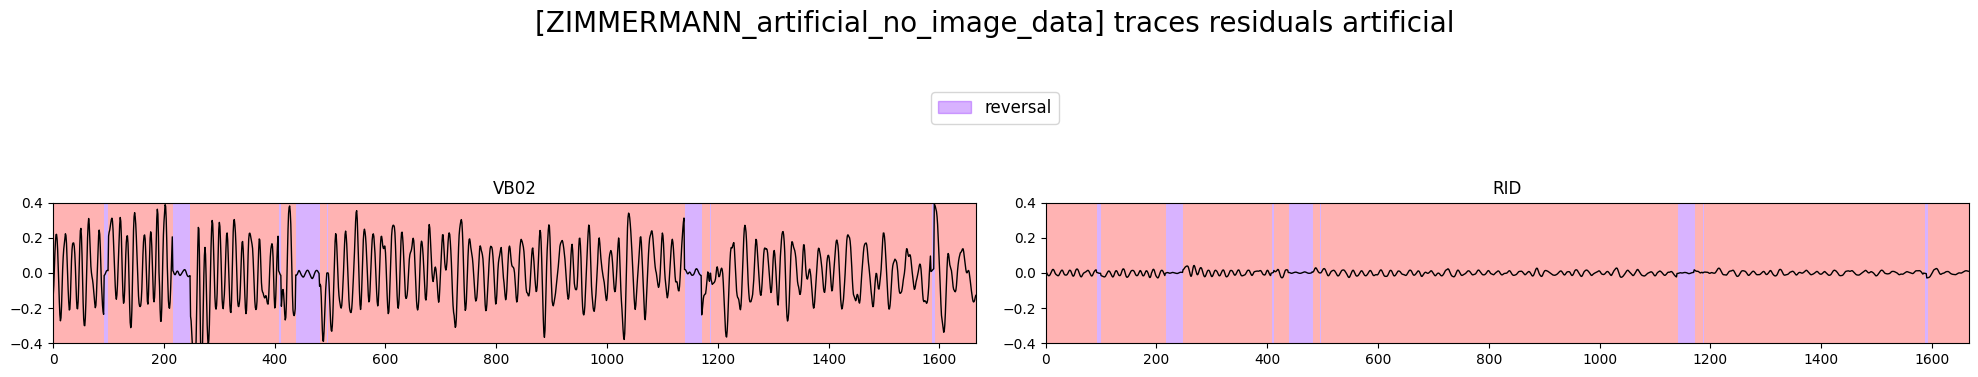

In [131]:
worm_id = 0

n_selection = ['VB02', 'RID']
plot_utils.plot_traces(traces_residual_art[worm_id][n_selection], discrete_states_art[worm_id]['REV'], f'[{filenames_art[worm_id]}] traces residuals artificial', n_plots=2, ylimits=(-0.4, 0.4))

In [132]:
# train alr art

(alr_models_models_art,
 alr_models_scores_art,
 alr_models_losses_art, alr_models_losses_tr_art) = fit_analytical_models(filenames_art,
																		  discrete_states_art,
																		  eigenworms_art,
																		  traces_residual_art)

1/5: ZIMMERMANN_artificial_no_image_data 2/5: ZIMMERMANN_artificial_no_image_data 3/5: ZIMMERMANN_artificial_wt_worm3-2023-11-21_no_image_data 4/5: ZIMMERMANN_artificial_worm10-2022-12-05_no_image_data 5/5: ZIMMERMANN_artificial_worm1-2022_11_28_no_image_data 

In [133]:
# train clm art

(clm_models_params_art,
 clm_models_scores_art,
 clm_models_losses_art, clm_models_losses_tr_art,
 clm_models_mse_losses_art, clm_models_mse_losses_tr_art,
 __clm_models_grads_art) = train_numerical_models(clm,
												  filenames_art,
												  discrete_states_art,
												  eigenworms_art,
												  traces_residual_art)

1/5: ZIMMERMANN_artificial_no_image_data  2/5: ZIMMERMANN_artificial_no_image_data  3/5: ZIMMERMANN_artificial_wt_worm3-2023-11-21_no_image_data  4/5: ZIMMERMANN_artificial_worm10-2022-12-05_no_image_data  5/5: ZIMMERMANN_artificial_worm1-2022_11_28_no_image_data  

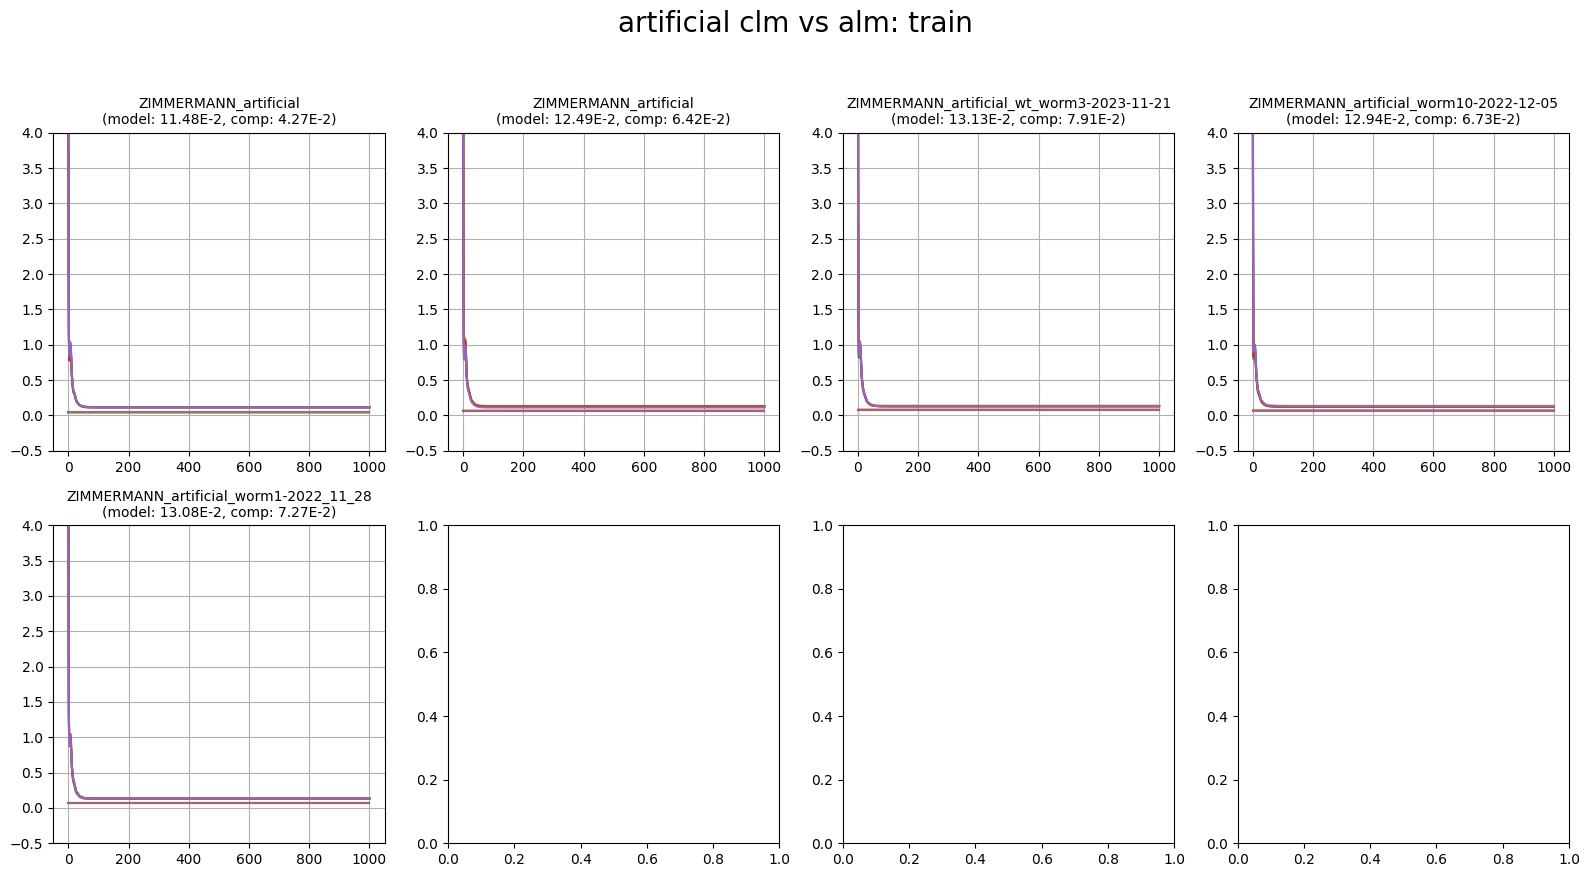

In [134]:
plot_utils.plot_losses(filenames_art, clm_models_losses_tr_art, [loss[:, None] * np.ones((1, clm_models_losses_tr_art[0].shape[1])) for loss in alr_models_losses_tr_art], 'artificial clm vs alm: train', None, (-0.1, 4))

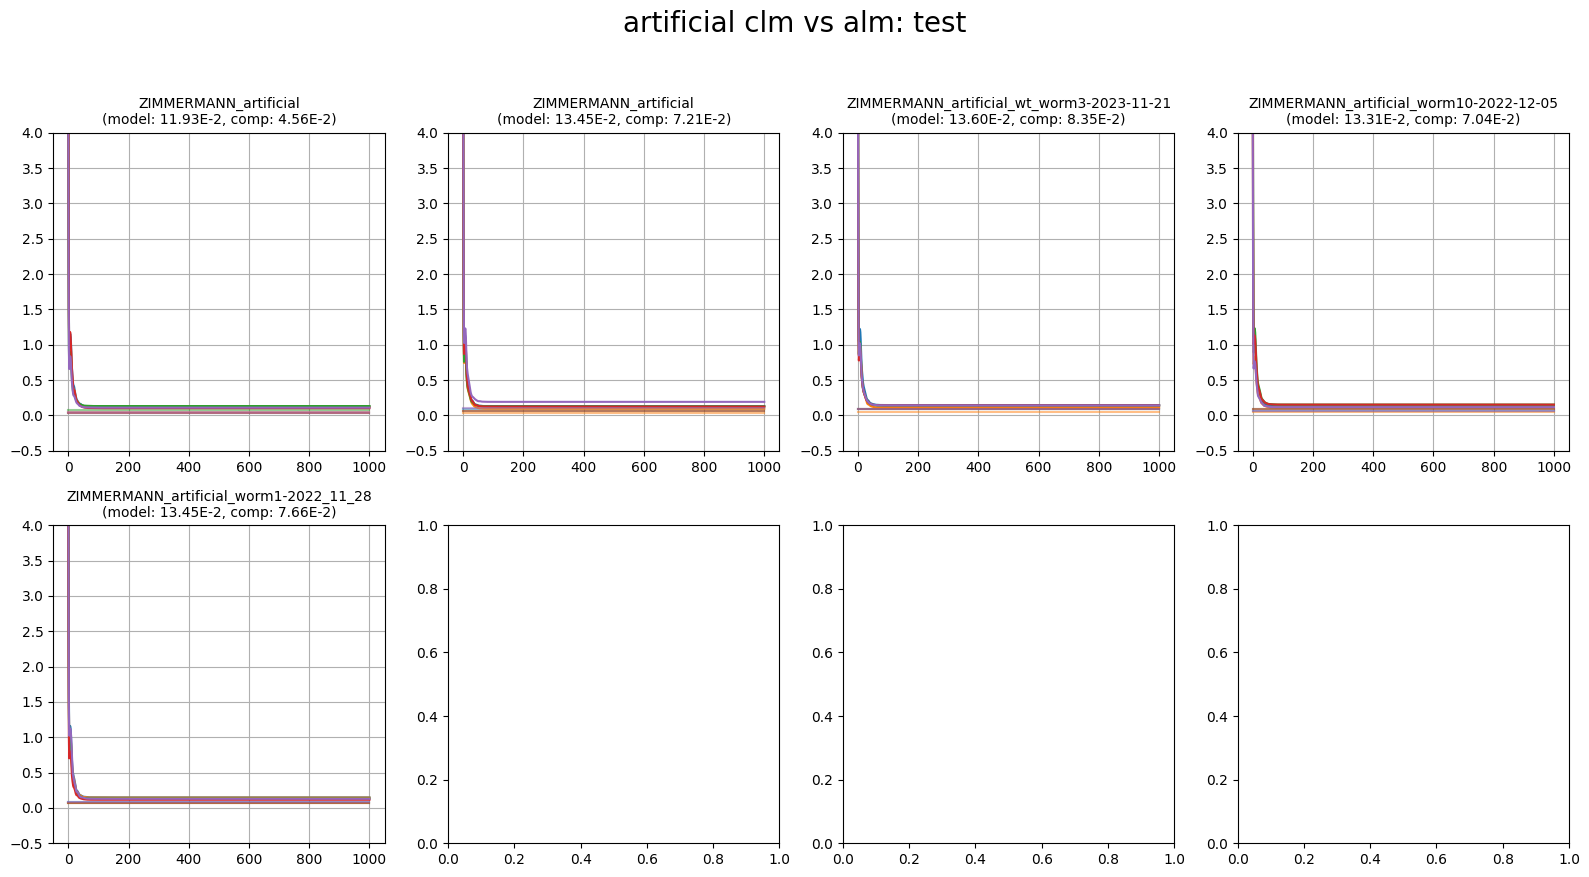

In [135]:
plot_utils.plot_losses(filenames_art, clm_models_losses_art, [loss[:, None] * np.ones((1, clm_models_losses_art[0].shape[1])) for loss in alr_models_losses_art], 'artificial clm vs alm: test', None, (-0.1, 4))

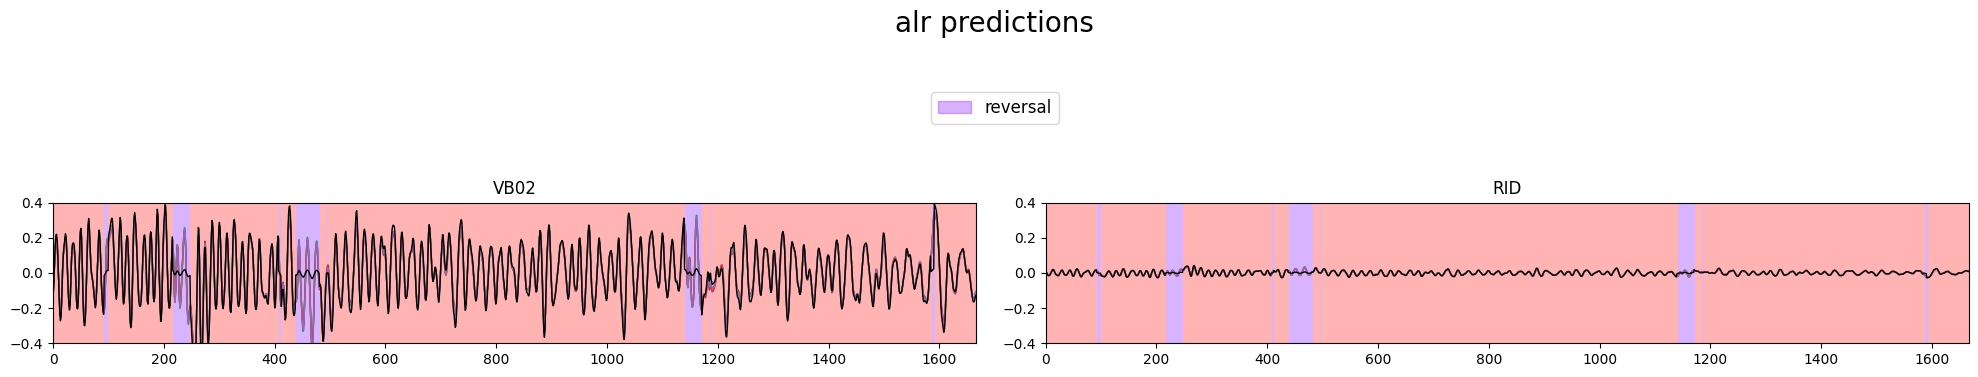

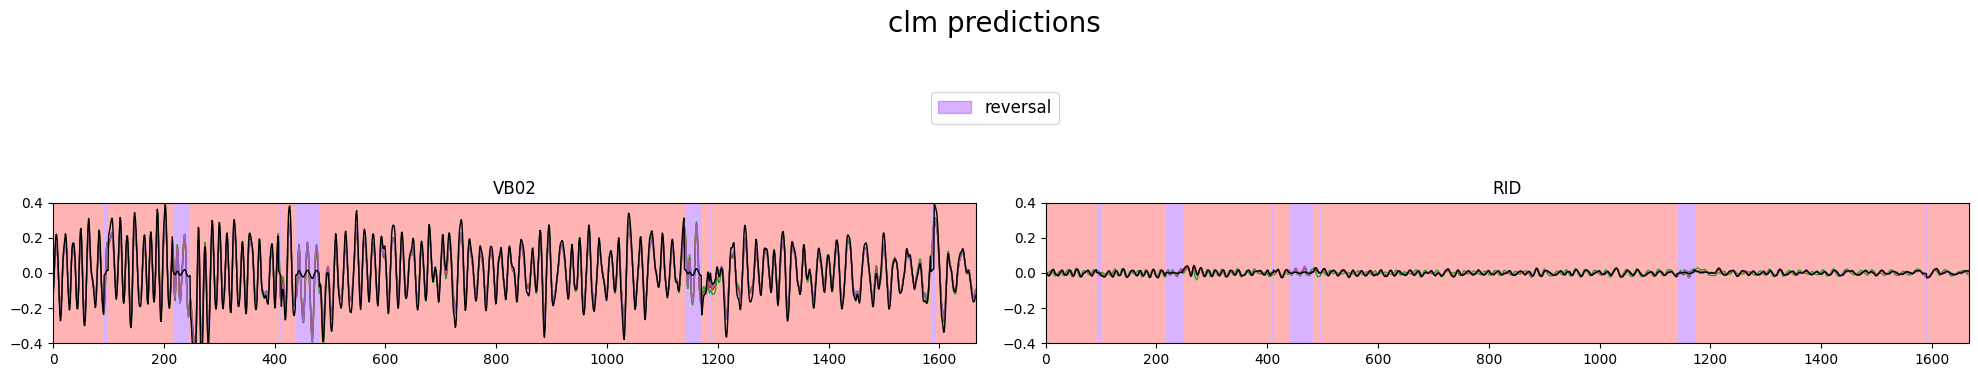

In [136]:
alr_predicted_traces = [[pd.DataFrame(data=model.predict(eigenworms_art[i].values), columns=traces_art[i].columns) for model in alr_models_models_art[i]] for i in range(len(traces_art))]
plot_utils.plot_traces(traces_residual_art[worm_id][n_selection], discrete_states_art[worm_id]['REV'], 'alr predictions', alr_predicted_traces[worm_id], ylimits=(-0.4, 0.4))

clm_predicted_traces = [[pd.DataFrame(data=clm.predict(eigenworms_art[i].values, params['W']), columns=traces_art[i].columns) for params in clm_models_params_art[i]] for i in range(len(traces_art))]
plot_utils.plot_traces(traces_residual_art[worm_id][n_selection], discrete_states_art[worm_id]['REV'], 'clm predictions', clm_predicted_traces[worm_id], ylimits=(-0.4, 0.4))

In [137]:
# train hgm art

(hgm_models_params_art,
 hgm_models_scores_art,
 hgm_models_losses_art, hgm_models_losses_tr_art,
 hgm_models_mse_losses_art, hgm_models_mse_losses_tr_art,
 __hgm_models_grads_art) = train_numerical_models(hgm,
												  filenames_art,
												  discrete_states_art,
												  eigenworms_art,
												  traces_residual_art,
												  modes_manifold_art)

1/5: ZIMMERMANN_artificial_no_image_data  2/5: ZIMMERMANN_artificial_no_image_data  3/5: ZIMMERMANN_artificial_wt_worm3-2023-11-21_no_image_data  4/5: ZIMMERMANN_artificial_worm10-2022-12-05_no_image_data  5/5: ZIMMERMANN_artificial_worm1-2022_11_28_no_image_data  

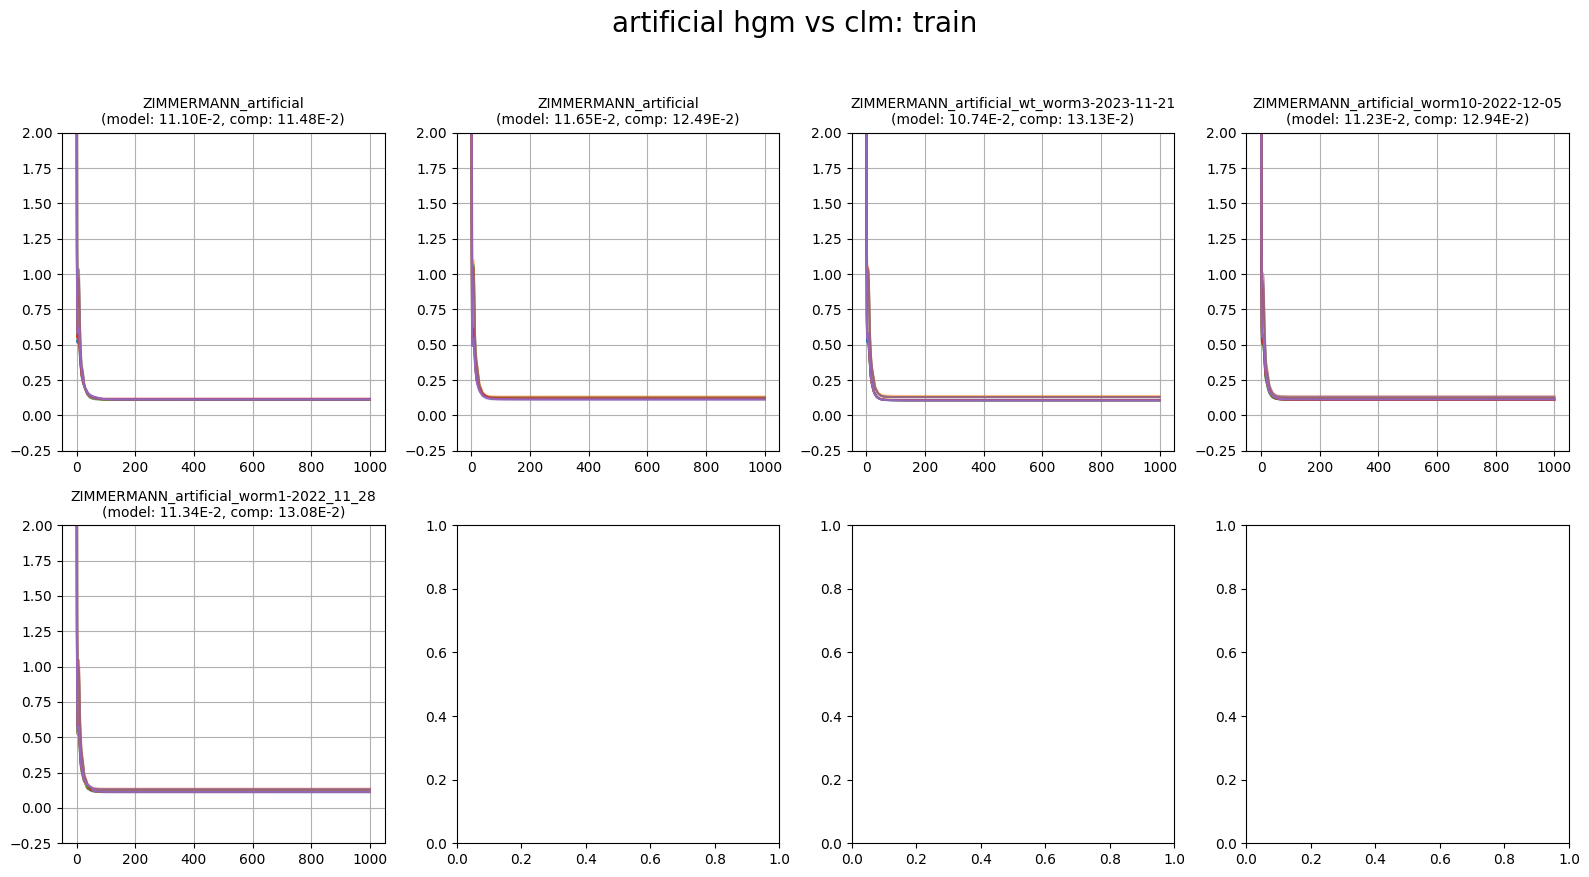

In [138]:
plot_utils.plot_losses(filenames_art, hgm_models_losses_tr_art, clm_models_losses_tr_art, 'artificial hgm vs clm: train', None, (-0.1, 2))

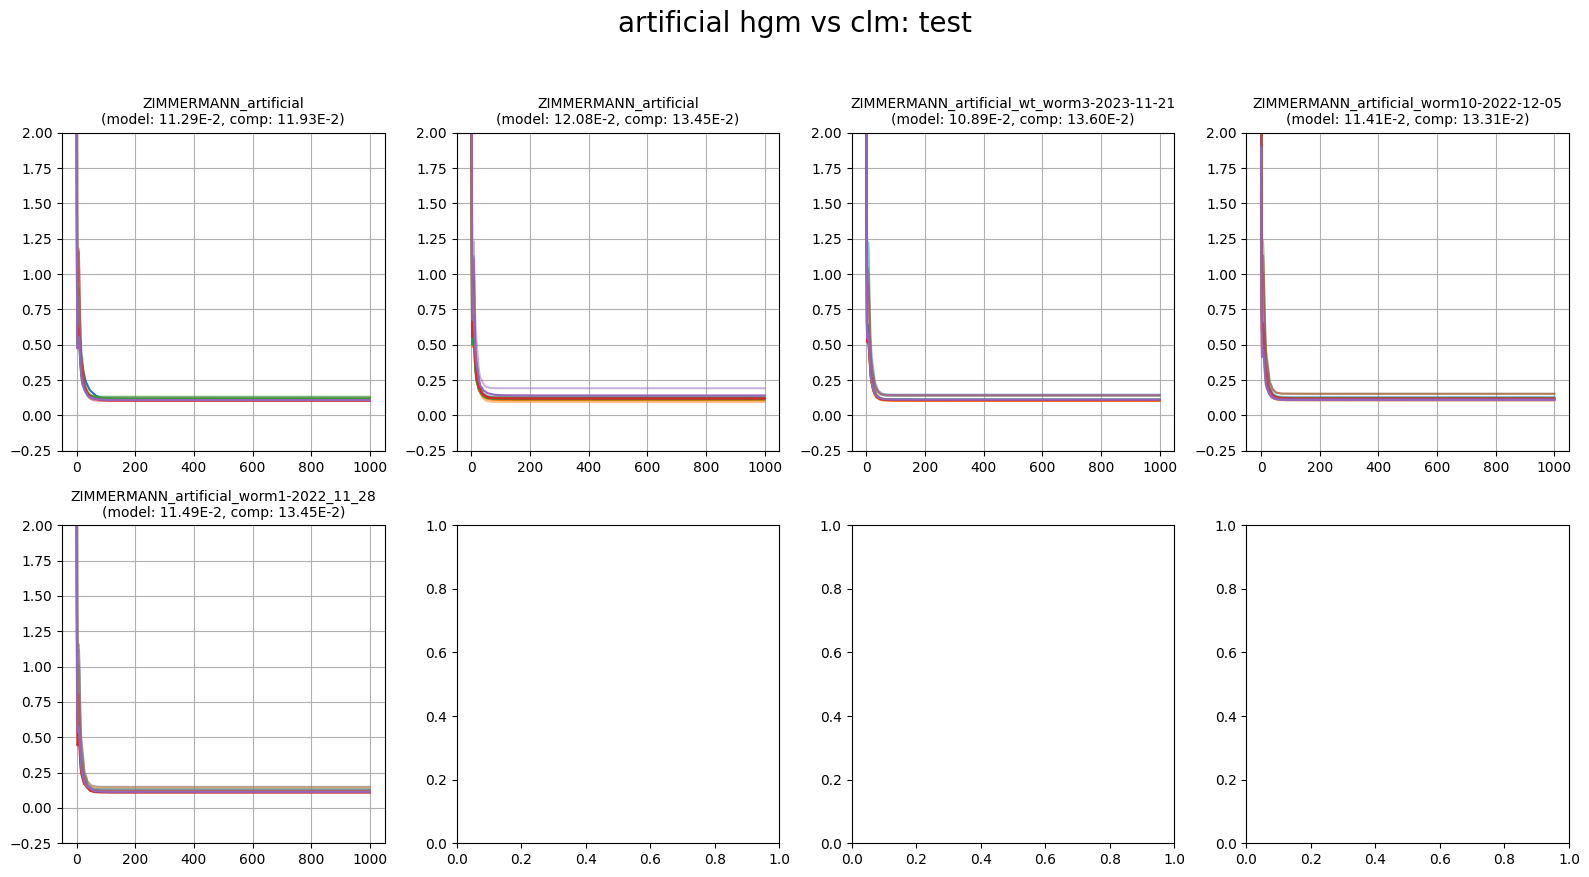

In [139]:
plot_utils.plot_losses(filenames_art, hgm_models_losses_art, clm_models_losses_art, 'artificial hgm vs clm: test', None, (-0.1, 2))

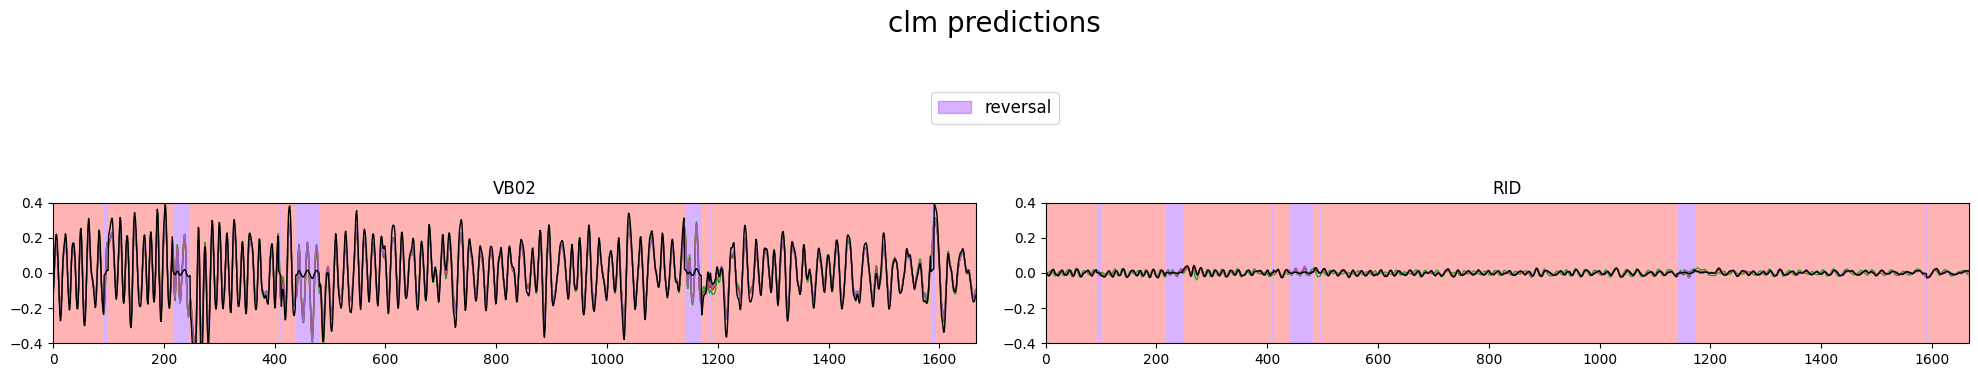

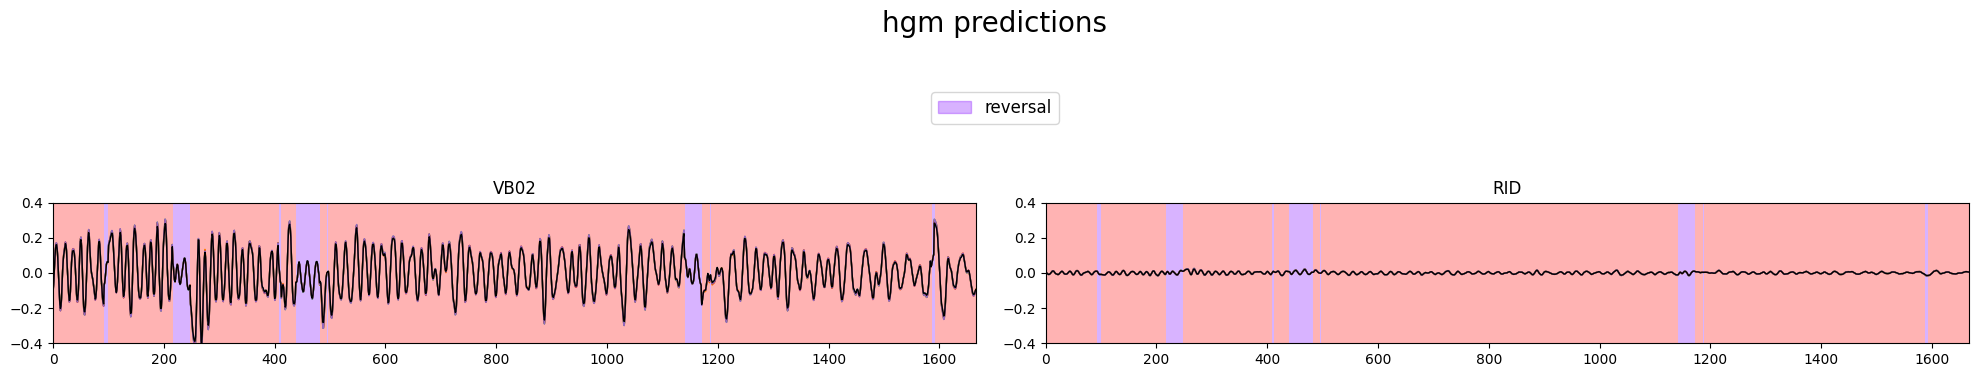

In [140]:
clm_predicted_traces = [[pd.DataFrame(data=clm.predict(eigenworms_art[i].values, params['W']), columns=traces_art[i].columns) for params in clm_models_params_art[i]] for i in range(len(traces_art))]
plot_utils.plot_traces(traces_residual_art[worm_id][n_selection], discrete_states_art[worm_id]['REV'], 'clm predictions', clm_predicted_traces[worm_id], ylimits=(-0.4, 0.4))

hgm_predicted_traces = [[pd.DataFrame(data=hgm.predict(eigenworms_art[i].values, modes_manifold_art[i].values, params['W1'], params['W2']), columns=traces_art[i].columns) for params in hgm_models_params_art[i]] for i in range(len(traces_art))]
# plot_utils.plot_traces(traces_residual_art[worm_id][n_selection], discrete_states_art[worm_id]['REV'], 'hgm predictions', hgm_predicted_traces[worm_id], limits=(-0.4, 0.4))
plot_utils.plot_traces(hgm_predicted_traces[worm_id][0][n_selection], discrete_states_art[worm_id]['REV'], 'hgm predictions', hgm_predicted_traces[worm_id], ylimits=(-0.4, 0.4))

In [141]:
# assemble_art

neuron_scores_art = assemble(filenames_art, traces_art, clm_models_scores_art, hgm_models_scores_art)

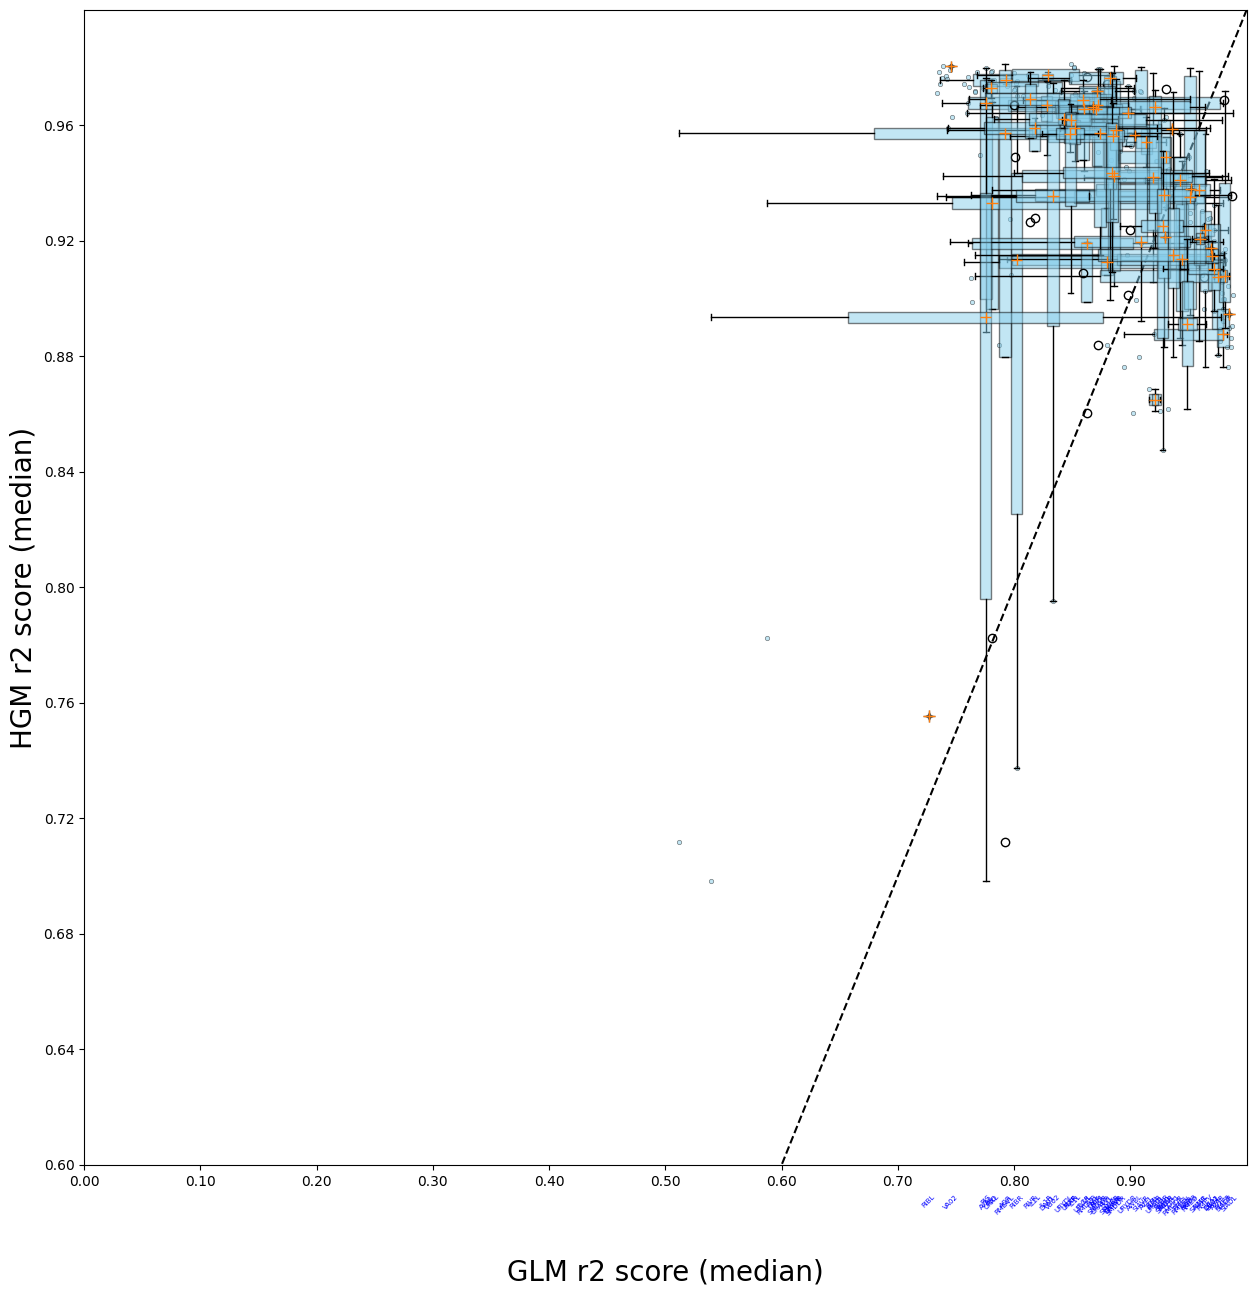

In [142]:
plot_utils.plot_performance_plot(neuron_scores_art, None, (0, 1, 0.6, 1), save=True)

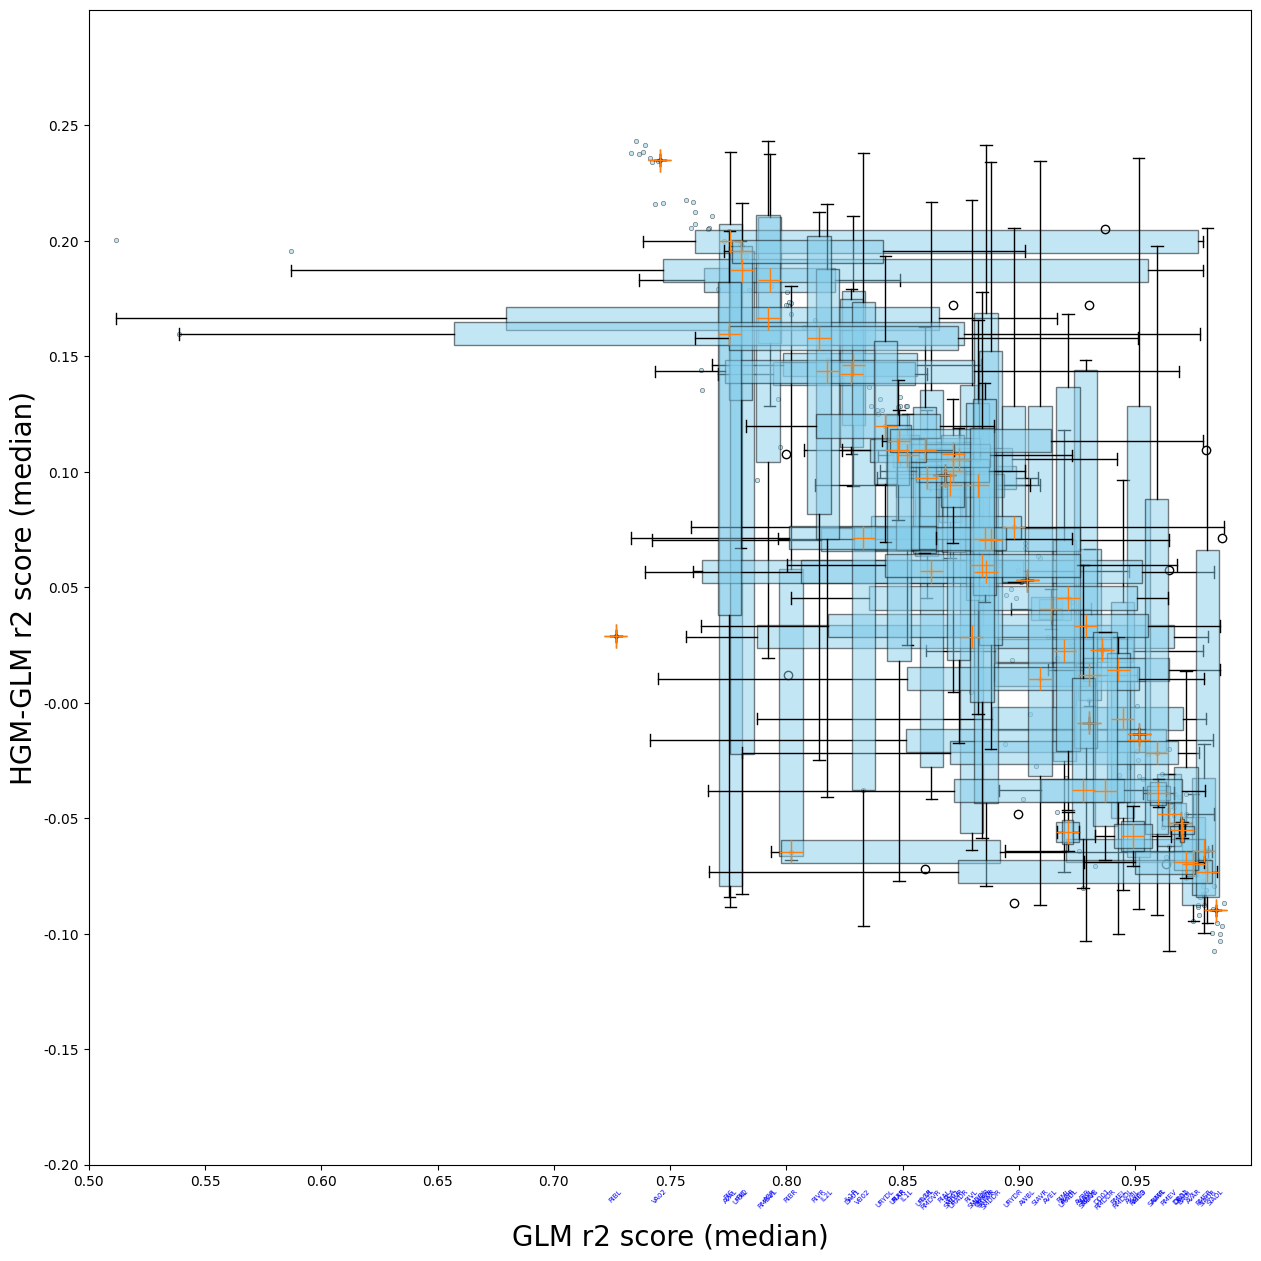

In [143]:
plot_utils.plot_improvement_plot(neuron_scores_art, None, (0.5, 1, -0.2, 0.3), save=True)

# ARTIFICIAL DATA END

In [144]:
if False: raise Exception

# GCAMP

### manifold

In [32]:
selection = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

(modes_manifold_gcamp, _,
 traces_manifold_gcamp, _,
 cca_loadings_man_gcamp,
 vars_expl_man_gcamp, vars_expl_man_rs_gcamp) = train_utils.get_manifolds(traces_gcamp,
																		  [ds[selection] for ds in discrete_states_gcamp],
																		  n_cc=2, n_pc=5)

# plot_utils.plot_manifolds(filenames_gcamp, modes_manifold_gcamp, vars_expl_man_gcamp, vars_expl_man_rs_gcamp, None)

0.49025736303662165 0.7391271473978394


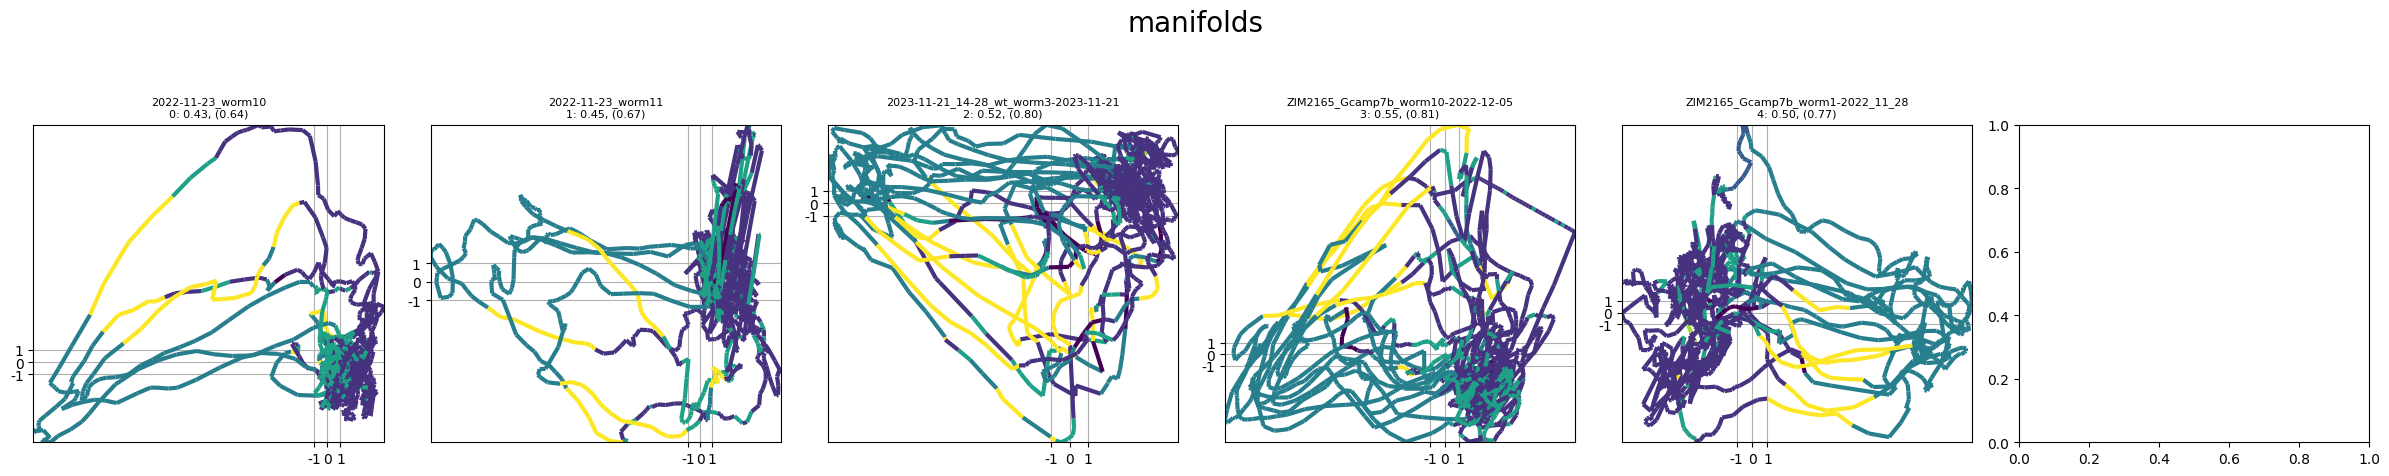

In [37]:
import importlib
importlib.reload(plot_utils)

plot_utils.plot_manifolds(filenames_gcamp, modes_manifold_gcamp, discrete_states_gcamp, vars_expl_man_gcamp, vars_expl_man_rs_gcamp, None)

In [146]:
traces_residual_gcamp = [pd.DataFrame(data=trace.values - trace_manifold.values, columns=trace.columns) for trace, trace_manifold in zip(traces_gcamp, traces_manifold_gcamp)]

### ALM

In [147]:
(alr_models_models_gcamp,
 alr_models_scores_gcamp,
 alr_models_losses_gcamp, alr_models_losses_tr_gcamp) = fit_analytical_models(filenames_gcamp,
																			  discrete_states_gcamp,
																			  eigenworms_gcamp,
																			  traces_residual_gcamp)

1/5: 2022-11-23_worm10_no_image_data 2/5: 2022-11-23_worm11_no_image_data 3/5: 2023-11-21_14-28_wt_worm3-2023-11-21_no_image_data 4/5: ZIM2165_Gcamp7b_worm10-2022-12-05_no_image_data 5/5: ZIM2165_Gcamp7b_worm1-2022_11_28_no_image_data 

### CLM

In [148]:
(clm_models_params_gcamp,
 clm_models_scores_gcamp,
 clm_models_losses_gcamp, clm_models_losses_tr_gcamp,
 clm_models_mse_losses_gcamp, clm_models_mse_losses_tr_gcamp,
 __clm_models_grads_gcamp) = train_numerical_models(clm,
													filenames_gcamp,
													discrete_states_gcamp,
													eigenworms_gcamp,
													traces_residual_gcamp)

1/5: 2022-11-23_worm10_no_image_data  2/5: 2022-11-23_worm11_no_image_data  3/5: 2023-11-21_14-28_wt_worm3-2023-11-21_no_image_data  4/5: ZIM2165_Gcamp7b_worm10-2022-12-05_no_image_data  5/5: ZIM2165_Gcamp7b_worm1-2022_11_28_no_image_data  

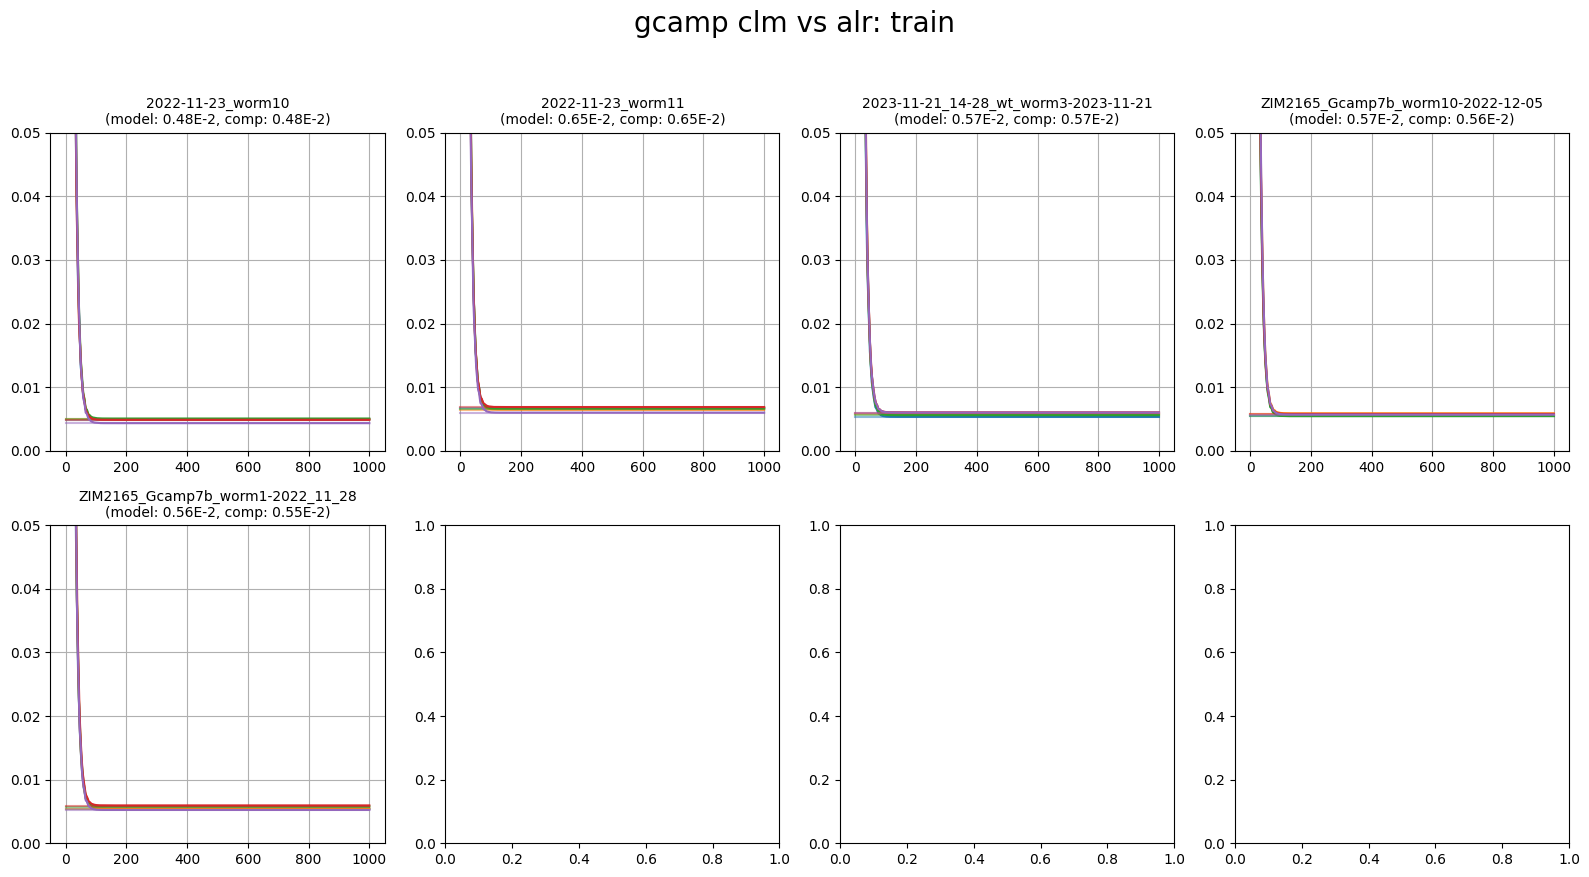

In [149]:
plot_utils.plot_losses(filenames_gcamp, clm_models_losses_tr_gcamp, [loss[:, None] * np.ones((1, clm_models_losses_tr_gcamp[0].shape[1])) for loss in alr_models_losses_tr_gcamp], 'gcamp clm vs alr: train', None, (0., 0.05))

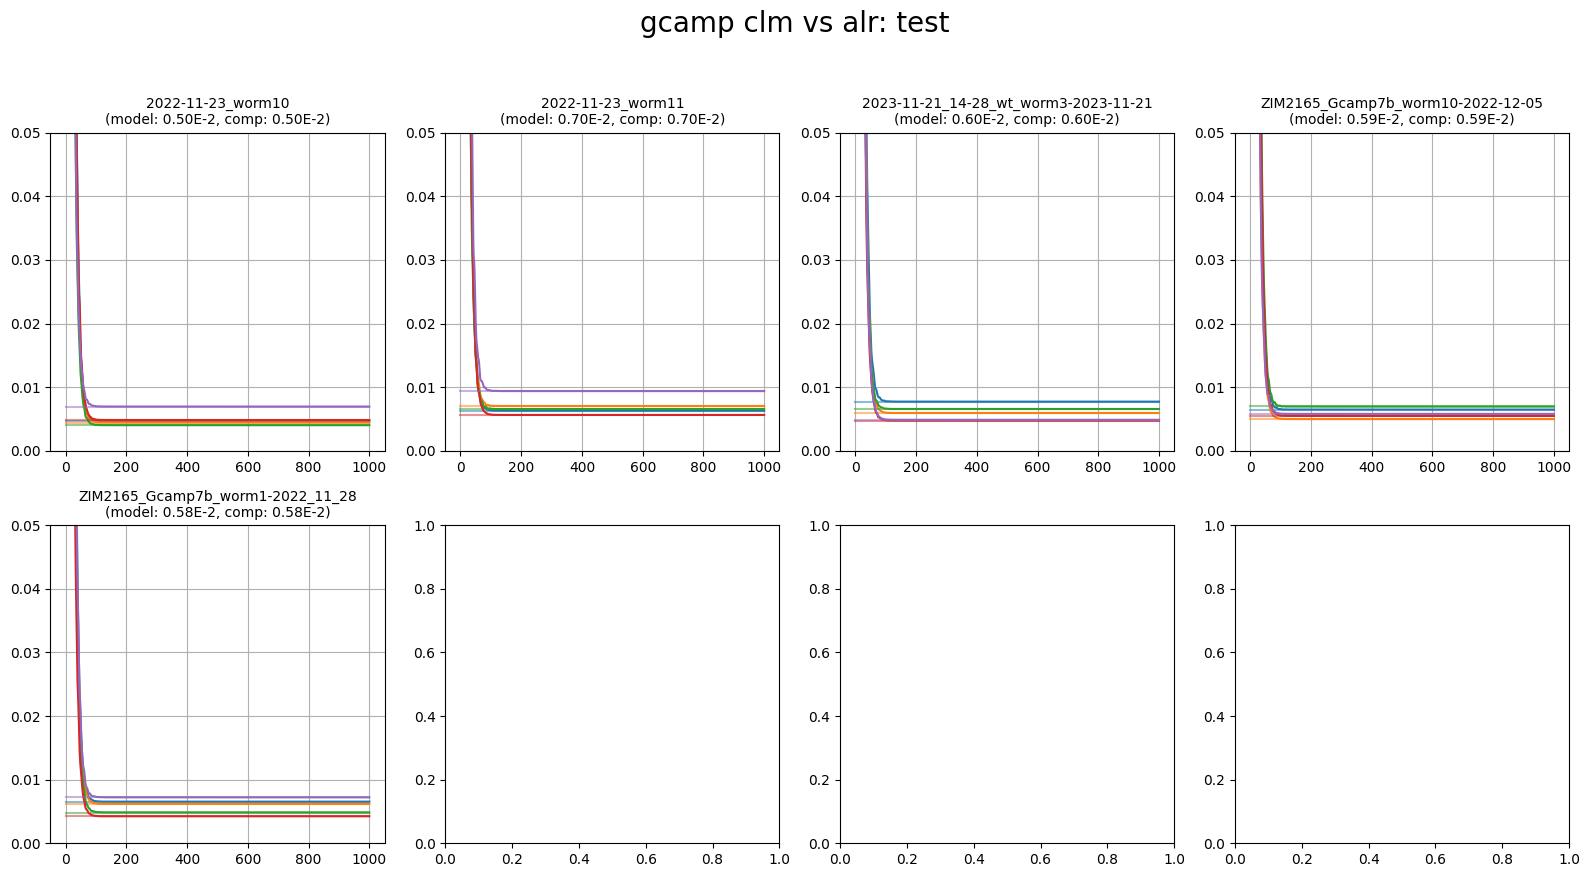

In [150]:
plot_utils.plot_losses(filenames_gcamp, clm_models_losses_gcamp, [loss[:, None] * np.ones((1, clm_models_losses_gcamp[0].shape[1])) for loss in alr_models_losses_gcamp], 'gcamp clm vs alr: test', None, (0., 0.05))

### HGM

In [151]:
(hgm_models_params_gcamp,
 hgm_models_scores_gcamp,
 hgm_models_losses_gcamp, hgm_models_losses_tr_gcamp,
 hgm_models_mse_losses_gcamp, hgm_models_mse_losses_tr_gcamp,
 __hgm_models_grads_gcamp) = train_numerical_models(hgm,
													filenames_gcamp,
													discrete_states_gcamp,
													eigenworms_gcamp,
													traces_residual_gcamp,
													modes_manifold_gcamp)

1/5: 2022-11-23_worm10_no_image_data  2/5: 2022-11-23_worm11_no_image_data  3/5: 2023-11-21_14-28_wt_worm3-2023-11-21_no_image_data  4/5: ZIM2165_Gcamp7b_worm10-2022-12-05_no_image_data  5/5: ZIM2165_Gcamp7b_worm1-2022_11_28_no_image_data  

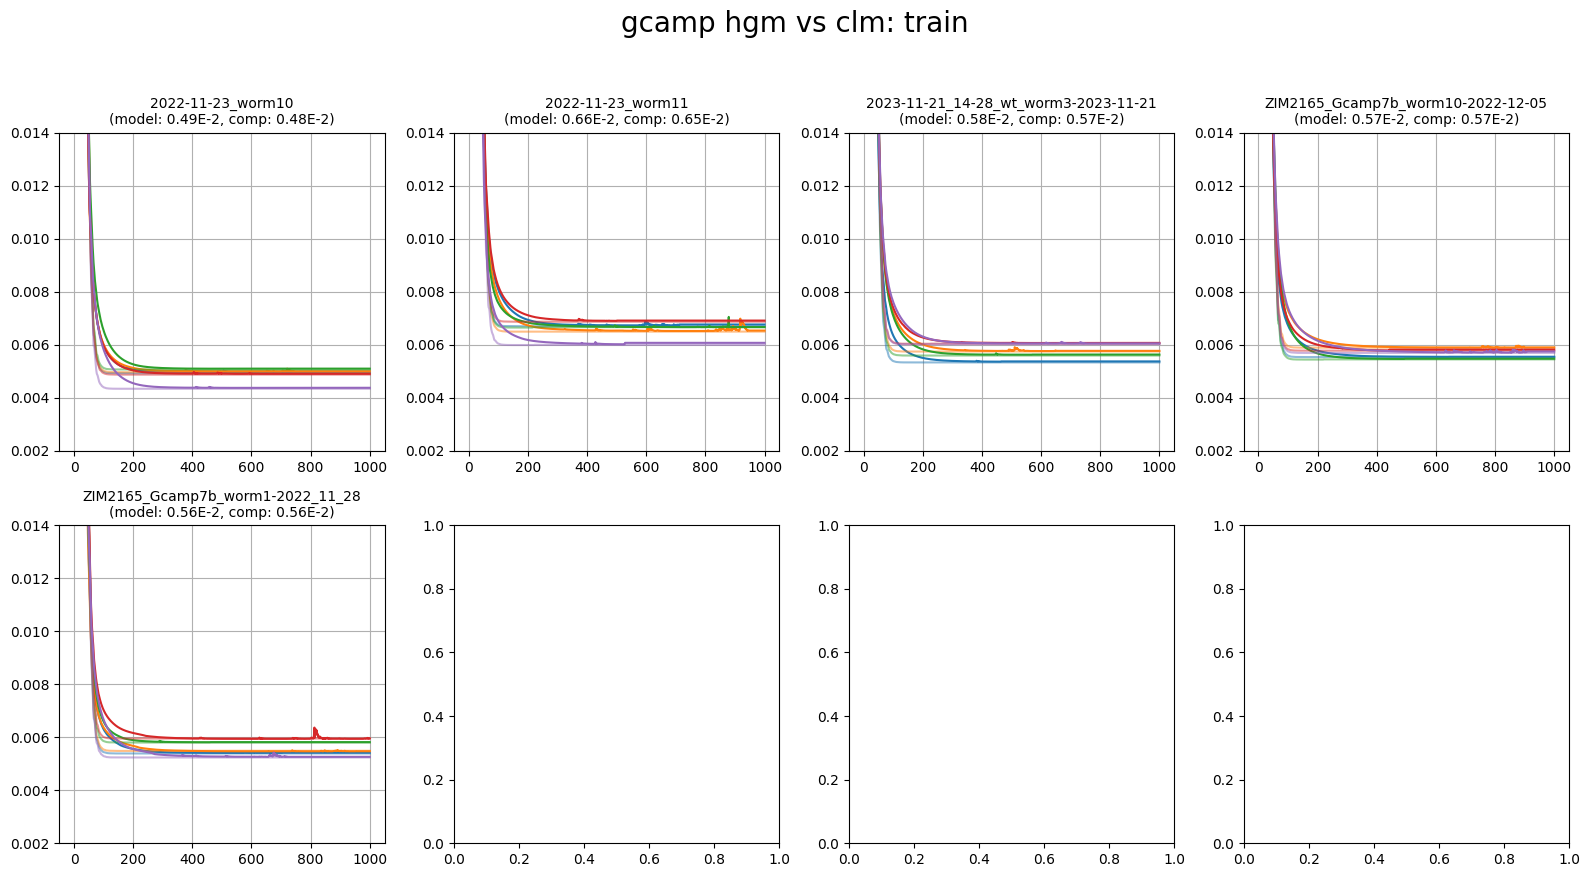

In [152]:
plot_utils.plot_losses(filenames_gcamp, hgm_models_losses_tr_gcamp, clm_models_losses_tr_gcamp, 'gcamp hgm vs clm: train', None, (0.003, 0.014))

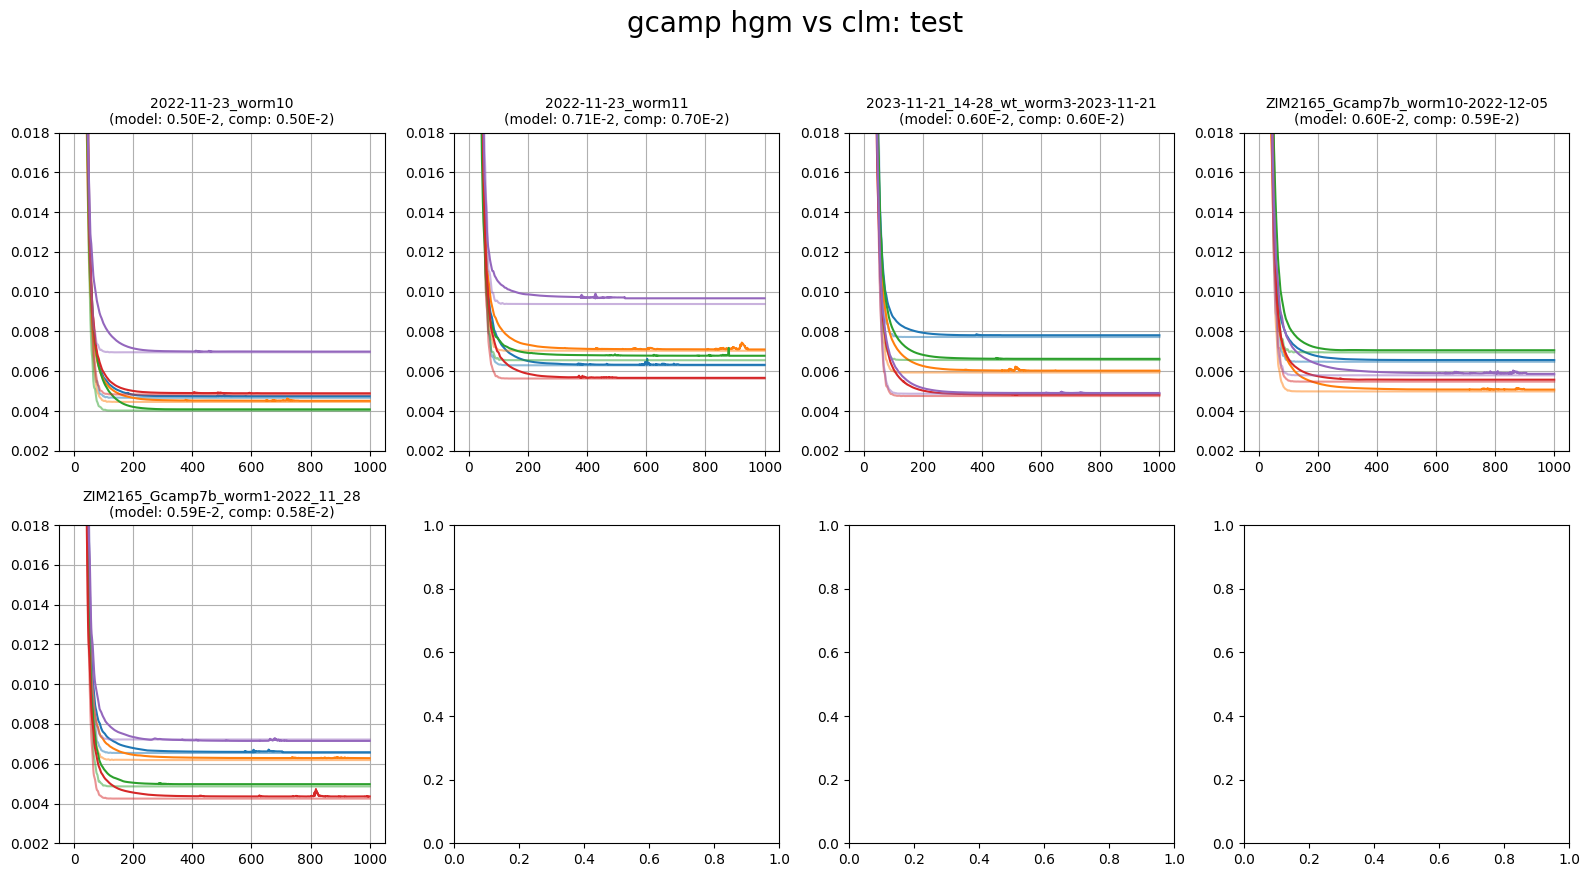

In [153]:
plot_utils.plot_losses(filenames_gcamp, hgm_models_losses_gcamp, clm_models_losses_gcamp, 'gcamp hgm vs clm: test', None, (0.003, 0.017))

### __loss gradient per weights over time

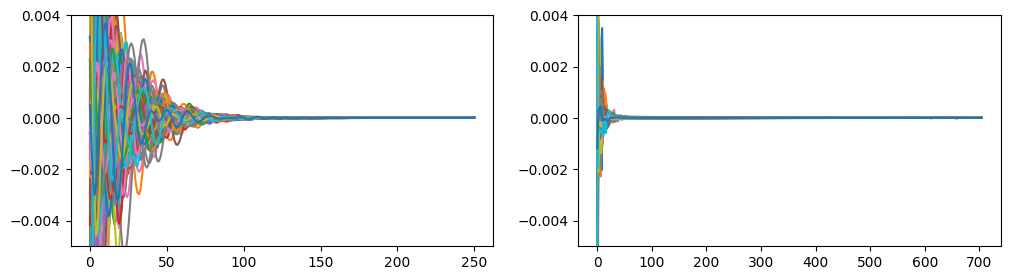

In [154]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
for ax in axes:
    ax.set_ylim(-0.005, 0.004)

for i in range(1):
	gradsW = np.array([val['W'] for val in __clm_models_grads_gcamp[-1][i]])

	gradsW1 = np.array([val['W1'] for val in __hgm_models_grads_gcamp[-1][i]])
	gradsW2 = np.array([val['W2'] for val in __hgm_models_grads_gcamp[-1][i]])


	axes[0].plot(np.mean(gradsW[:, :], axis=1))

	# axes[1].plot(np.mean(gradsW1[:, :, 10], axis=1))
	axes[1].plot(np.mean(gradsW2[:, :], axis=1))

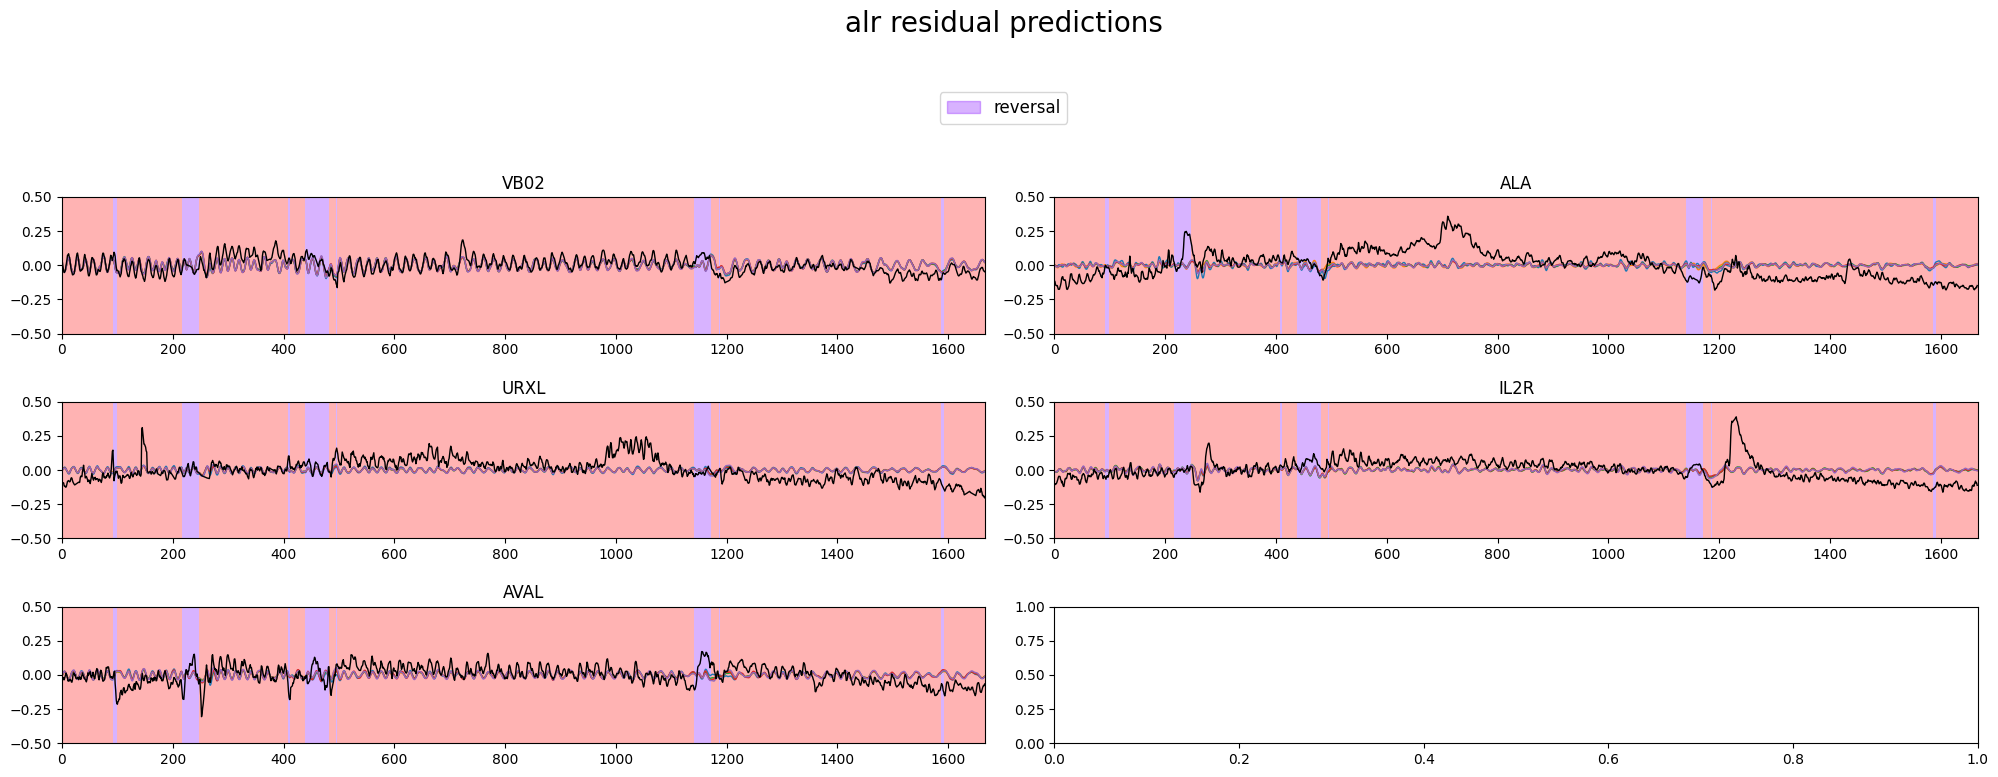

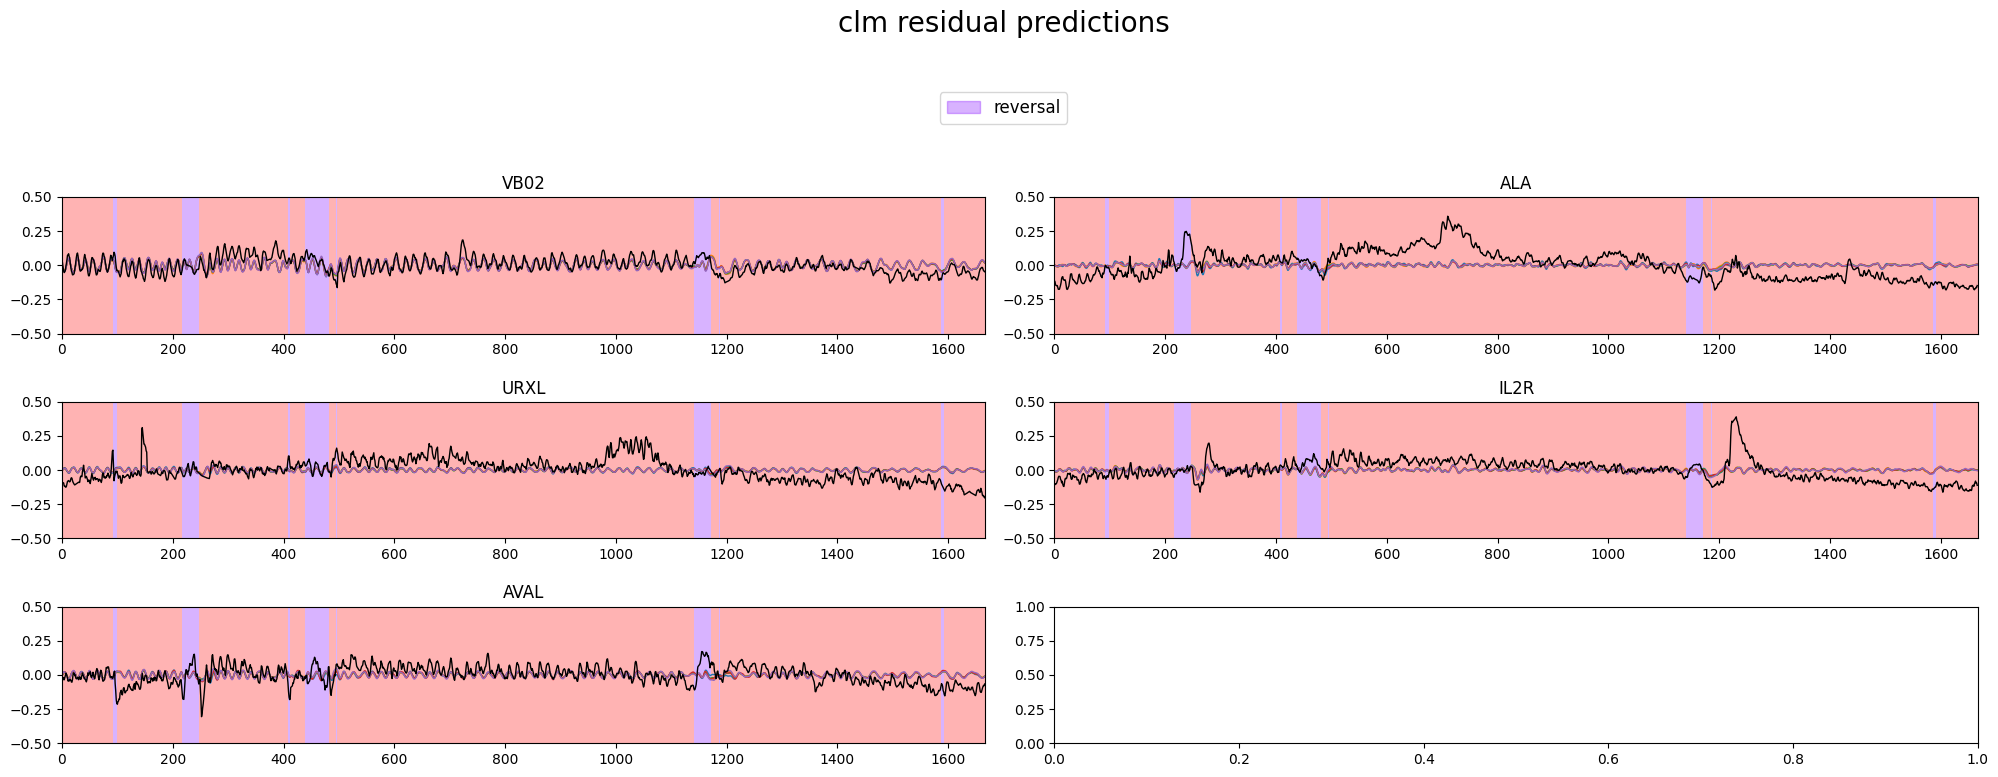

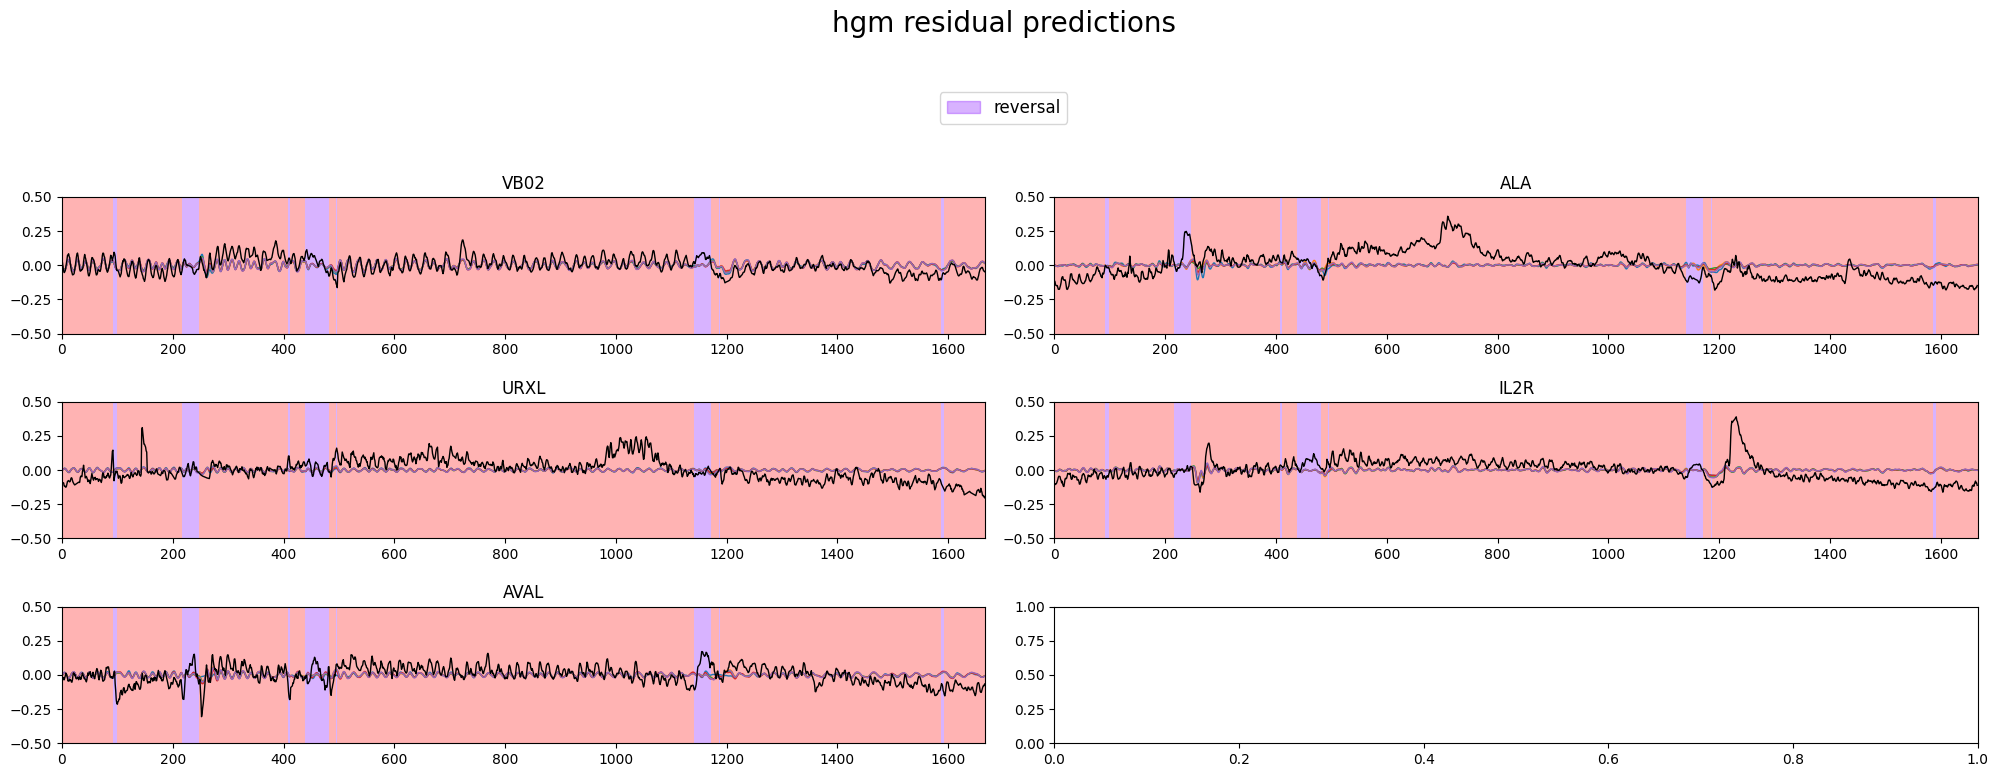

In [165]:
n_selection = ['VB02', 'ALA', 'URXL', 'IL2R', 'AVAL']

alr_predicted_traces = [[pd.DataFrame(data=model.predict(eigenworms_gcamp[i].values), columns=traces_gcamp[i].columns) for model in alr_models_models_gcamp[i]] for i in range(len(traces_gcamp))]
plot_utils.plot_traces(traces_residual_gcamp[worm_id][n_selection], discrete_states_gcamp[worm_id]['REV'], 'alr residual predictions', alr_predicted_traces[worm_id], ylimits=(-0.5, 0.5))

clm_predicted_traces = [[pd.DataFrame(data=clm.predict(eigenworms_gcamp[i].values, params['W']), columns=traces_gcamp[i].columns) for params in clm_models_params_gcamp[i]] for i in range(len(traces_gcamp))]
plot_utils.plot_traces(traces_residual_gcamp[worm_id][n_selection], discrete_states_gcamp[worm_id]['REV'], 'clm residual predictions', clm_predicted_traces[worm_id], ylimits=(-0.5, 0.5))

hgm_predicted_traces = [[pd.DataFrame(data=hgm.predict(eigenworms_gcamp[i].values, modes_manifold_gcamp[i].values, params['W1'], params['W2']), columns=traces_gcamp[i].columns) for params in hgm_models_params_gcamp[i]] for i in range(len(traces_gcamp))]
plot_utils.plot_traces(traces_residual_gcamp[worm_id][n_selection], discrete_states_gcamp[worm_id]['REV'], 'hgm residual predictions', hgm_predicted_traces[worm_id], ylimits=(-0.5, 0.5))

# GFP

### manifold

In [156]:
selection = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

(modes_manifold_gfp,
 traces_manifold_gfp,
 cca_loadings_man_gfp,
 vars_expl_man_gfp,
 vars_expl_man_rs_gfp) = train_utils.get_manifolds(traces_gfp,
												   [ds[selection] for ds in discrete_states_gfp],
												   n_cc=2, n_pc=5)

# plot_utils.plot_manifolds(filenames_gfp, modes_manifold_gfp, vars_expl_man_gfp, vars_expl_man_rs_gfp)

In [157]:
traces_residual_gfp = [pd.DataFrame(data=trace.values - trace_manifold.values, columns=trace.columns) for trace, trace_manifold in zip(traces_gfp, traces_manifold_gfp)]

### ALM

In [158]:
(alr_models_models_gfp,
 alr_models_scores_gfp,
 alr_models_losses_gfp, alr_models_losses_tr_gfp) = fit_analytical_models(filenames_gfp,
																		  discrete_states_gfp,
																		  eigenworms_gfp,
																		  traces_residual_gfp)

1/8: ZIM2319_GFP_worm3-2022-12-10_no_image_data 2/8: ZIM2319_GFP_worm1-2022-12-10_no_image_data 3/8: ZIM2319_GFP_worm2-2022-12-10_no_image_data 4/8: ZIM2319_GFP_worm6-2022-12-10_no_image_data 5/8: ZIM2319_GFP_worm8-2022-12-10_no_image_data 6/8: ZIM2319_GFP_worm4-2022-12-10_no_image_data 7/8: ZIM2319_GFP_worm7-2022-12-10_no_image_data 8/8: ZIM2319_GFP_worm5-2022-12-10_no_image_data 

### CLM

In [159]:
(clm_models_params_gfp,
 clm_models_scores_gfp,
 clm_models_losses_gfp, clm_models_losses_tr_gfp,
 clm_models_mse_losses_gfp, clm_models_mse_losses_tr_gfp,
 __clm_models_grads_gfp) = train_numerical_models(clm,
												  filenames_gfp,
												  discrete_states_gfp,
												  eigenworms_gfp,
												  traces_residual_gfp)

1/8: ZIM2319_GFP_worm3-2022-12-10_no_image_data  2/8: ZIM2319_GFP_worm1-2022-12-10_no_image_data  3/8: ZIM2319_GFP_worm2-2022-12-10_no_image_data  4/8: ZIM2319_GFP_worm6-2022-12-10_no_image_data  5/8: ZIM2319_GFP_worm8-2022-12-10_no_image_data  6/8: ZIM2319_GFP_worm4-2022-12-10_no_image_data  7/8: ZIM2319_GFP_worm7-2022-12-10_no_image_data  8/8: ZIM2319_GFP_worm5-2022-12-10_no_image_data  

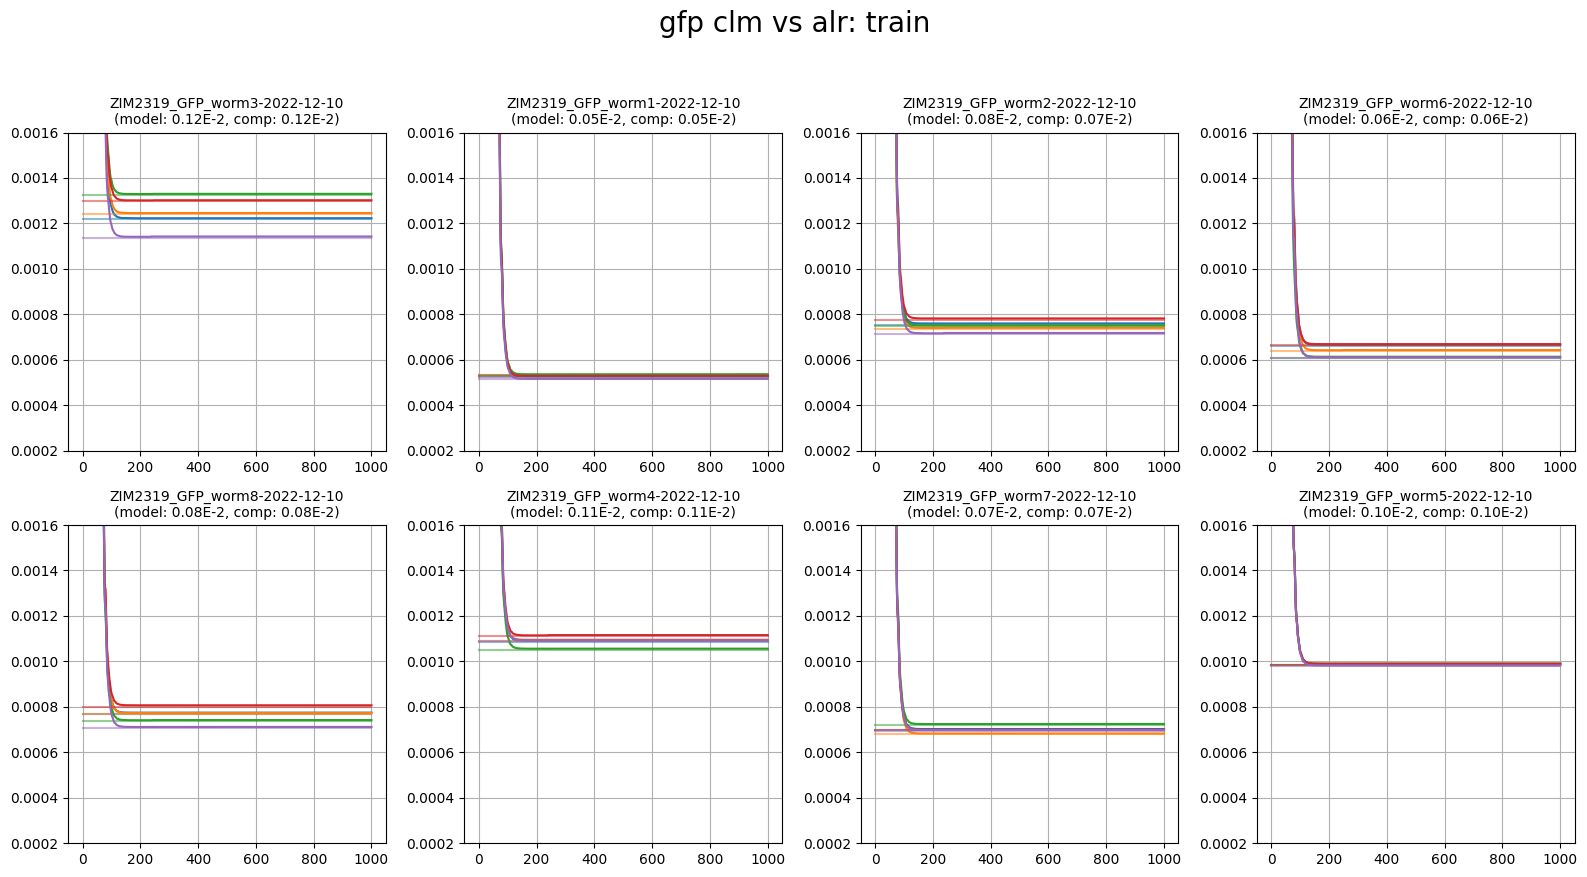

In [160]:
plot_utils.plot_losses(filenames_gfp, clm_models_losses_tr_gfp, [loss[:, None] * np.ones((1, clm_models_losses_tr_gfp[0].shape[1])) for loss in alr_models_losses_tr_gfp], 'gfp clm vs alr: train', None, (0.00025, 0.0015))

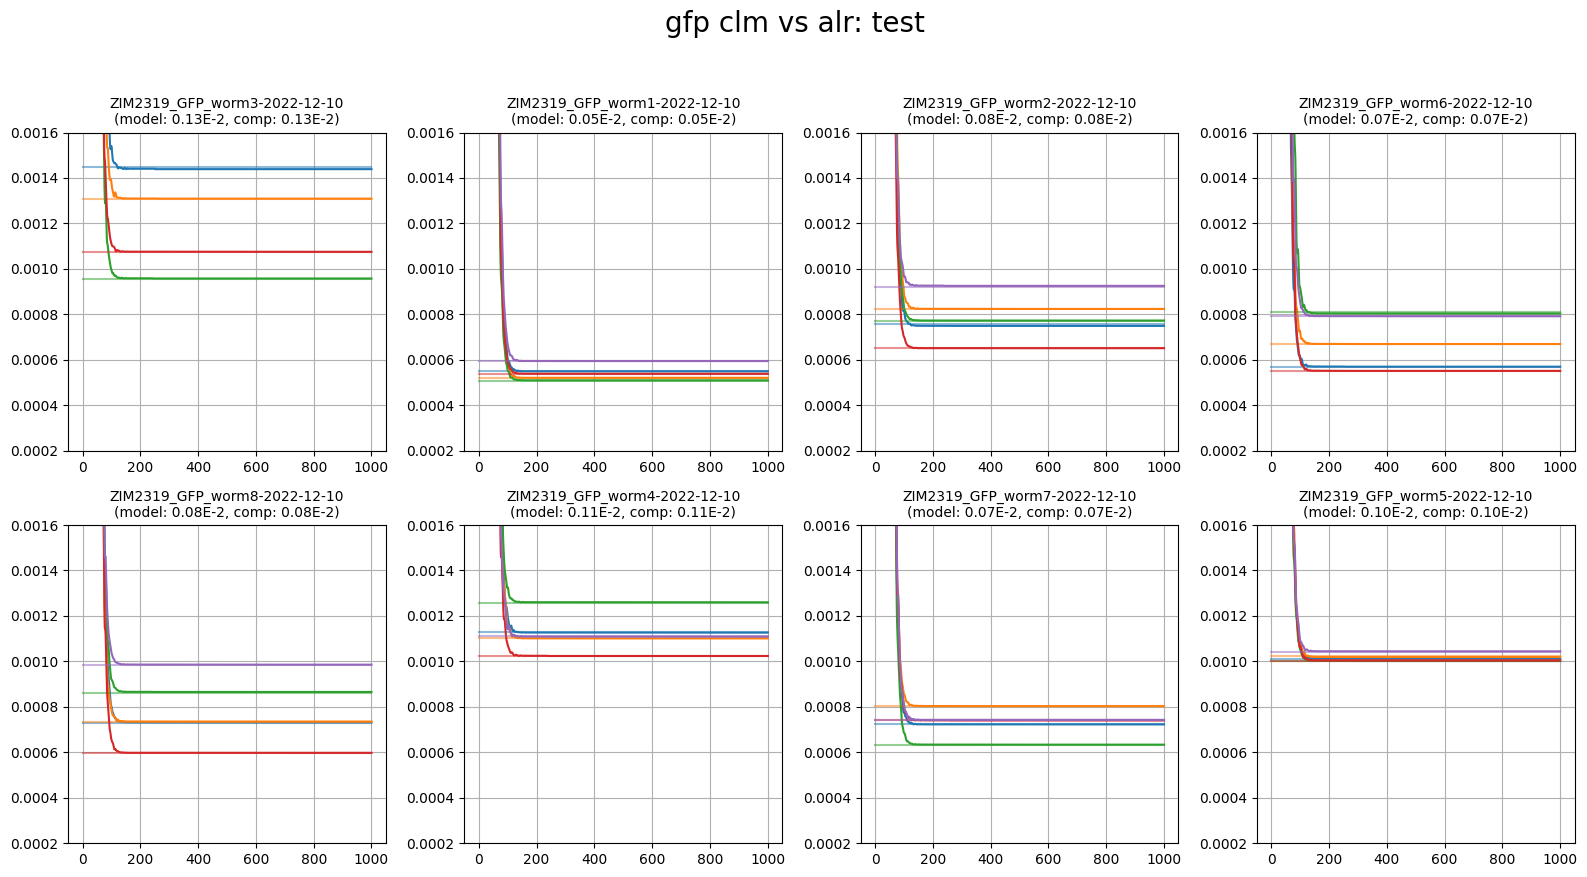

In [161]:
plot_utils.plot_losses(filenames_gfp, clm_models_losses_gfp, [loss[:, None] * np.ones((1, clm_models_losses_gfp[0].shape[1])) for loss in alr_models_losses_gfp], 'gfp clm vs alr: test', None, (0.00025, 0.0015))

### HGM

In [166]:
(hgm_models_params_gfp,
 hgm_models_scores_gfp,
 hgm_models_losses_gfp, hgm_models_losses_tr_gfp,
 hgm_models_mse_losses_gfp, hgm_models_mse_losses_tr_gfp,
 __hgm_models_grads_gfp) = train_numerical_models(hgm,
												  filenames_gfp,
												  discrete_states_gfp,
												  eigenworms_gfp,
												  traces_residual_gfp,
												  modes_manifold_gfp)

1/8: ZIM2319_GFP_worm3-2022-12-10_no_image_data  2/8: ZIM2319_GFP_worm1-2022-12-10_no_image_data  3/8: ZIM2319_GFP_worm2-2022-12-10_no_image_data  4/8: ZIM2319_GFP_worm6-2022-12-10_no_image_data  5/8: ZIM2319_GFP_worm8-2022-12-10_no_image_data  6/8: ZIM2319_GFP_worm4-2022-12-10_no_image_data  7/8: ZIM2319_GFP_worm7-2022-12-10_no_image_data  8/8: ZIM2319_GFP_worm5-2022-12-10_no_image_data  

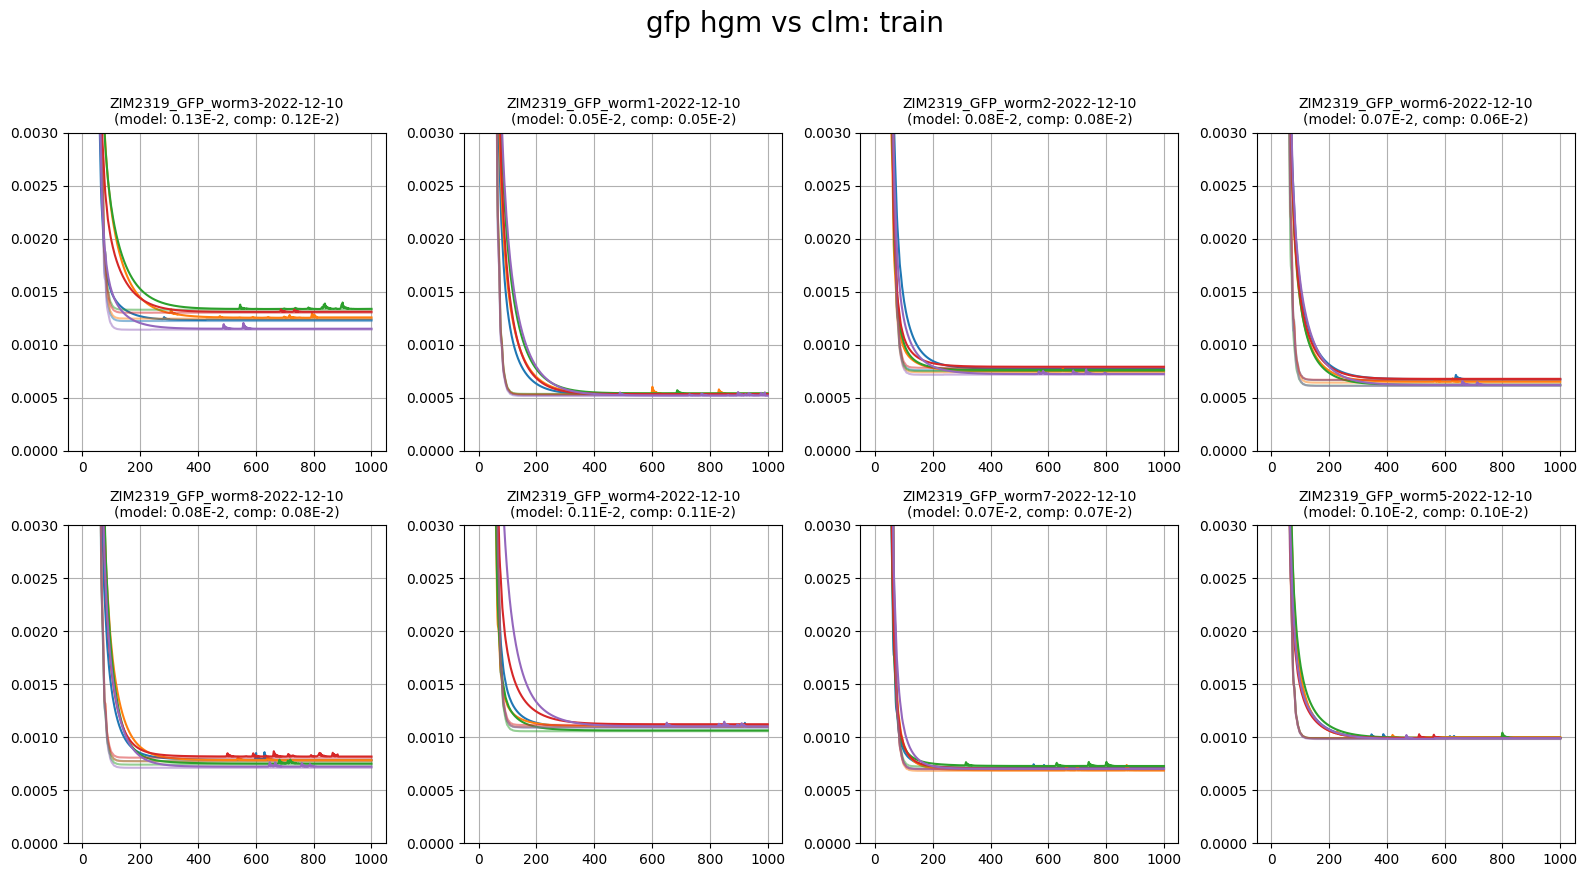

In [167]:
plot_utils.plot_losses(filenames_gfp, hgm_models_losses_tr_gfp, clm_models_losses_tr_gfp, 'gfp hgm vs clm: train', None, (0.0, 0.003))

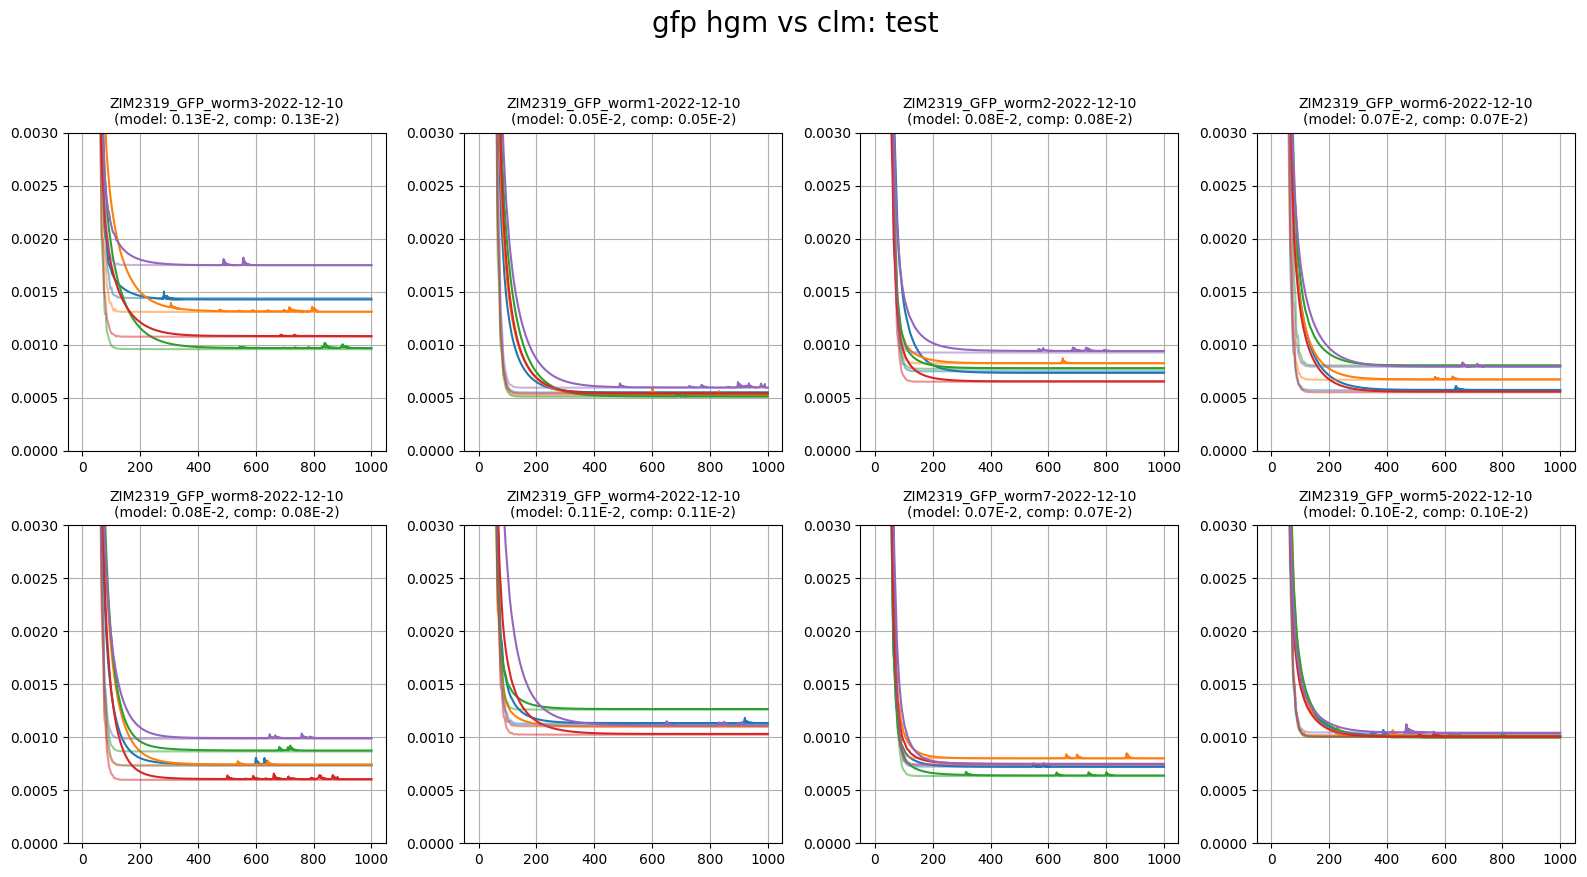

In [168]:
plot_utils.plot_losses(filenames_gfp, hgm_models_losses_gfp, clm_models_losses_gfp, 'gfp hgm vs clm: test', None, (0.0, 0.003))

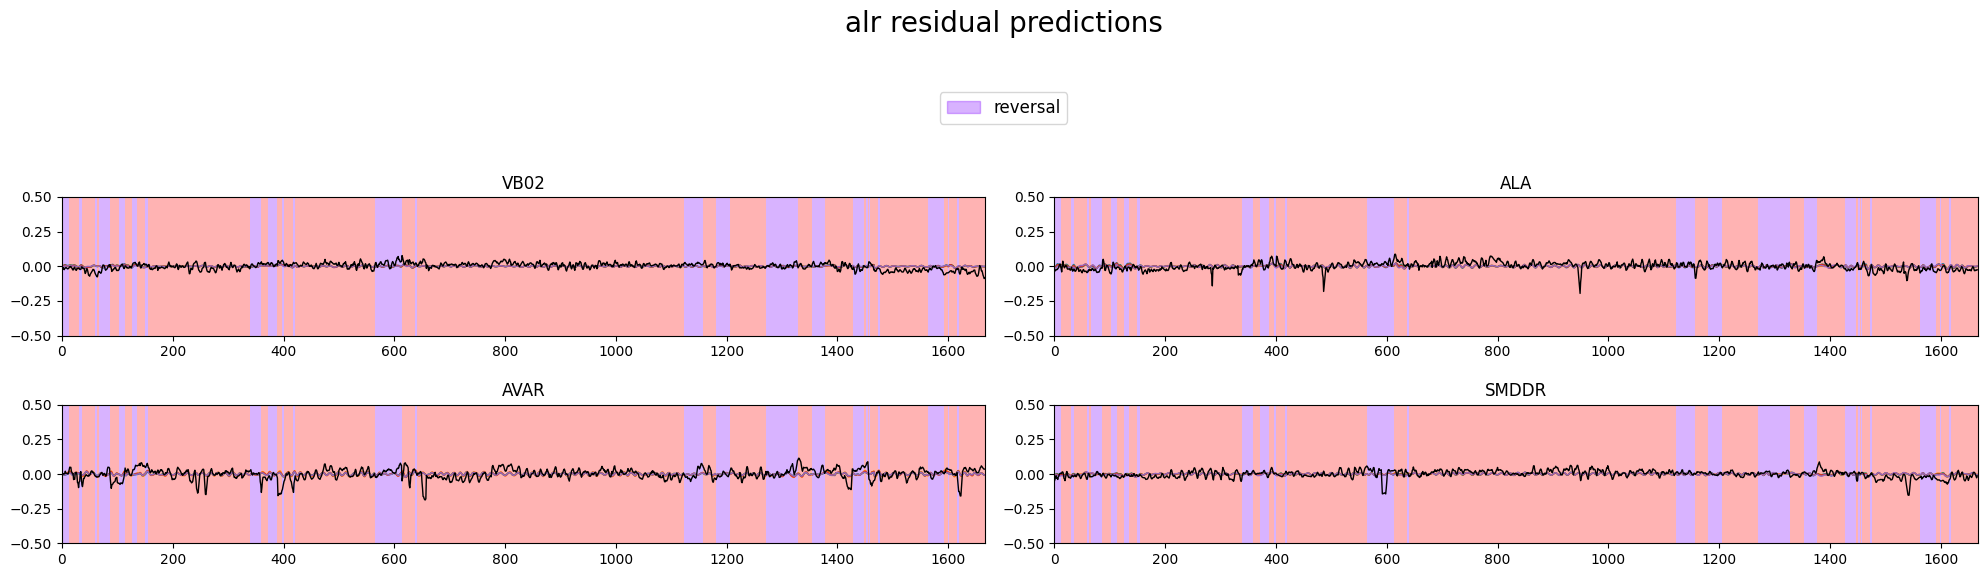

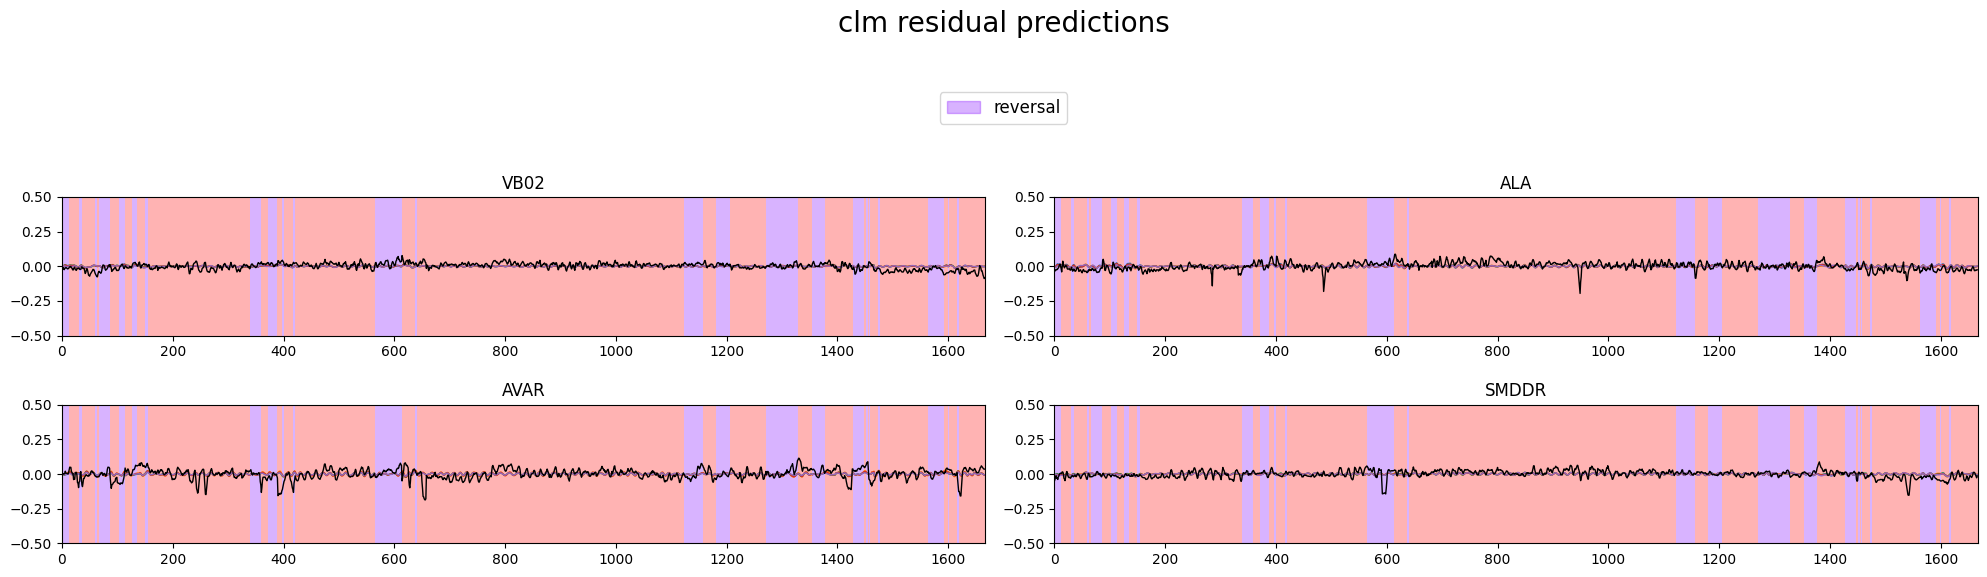

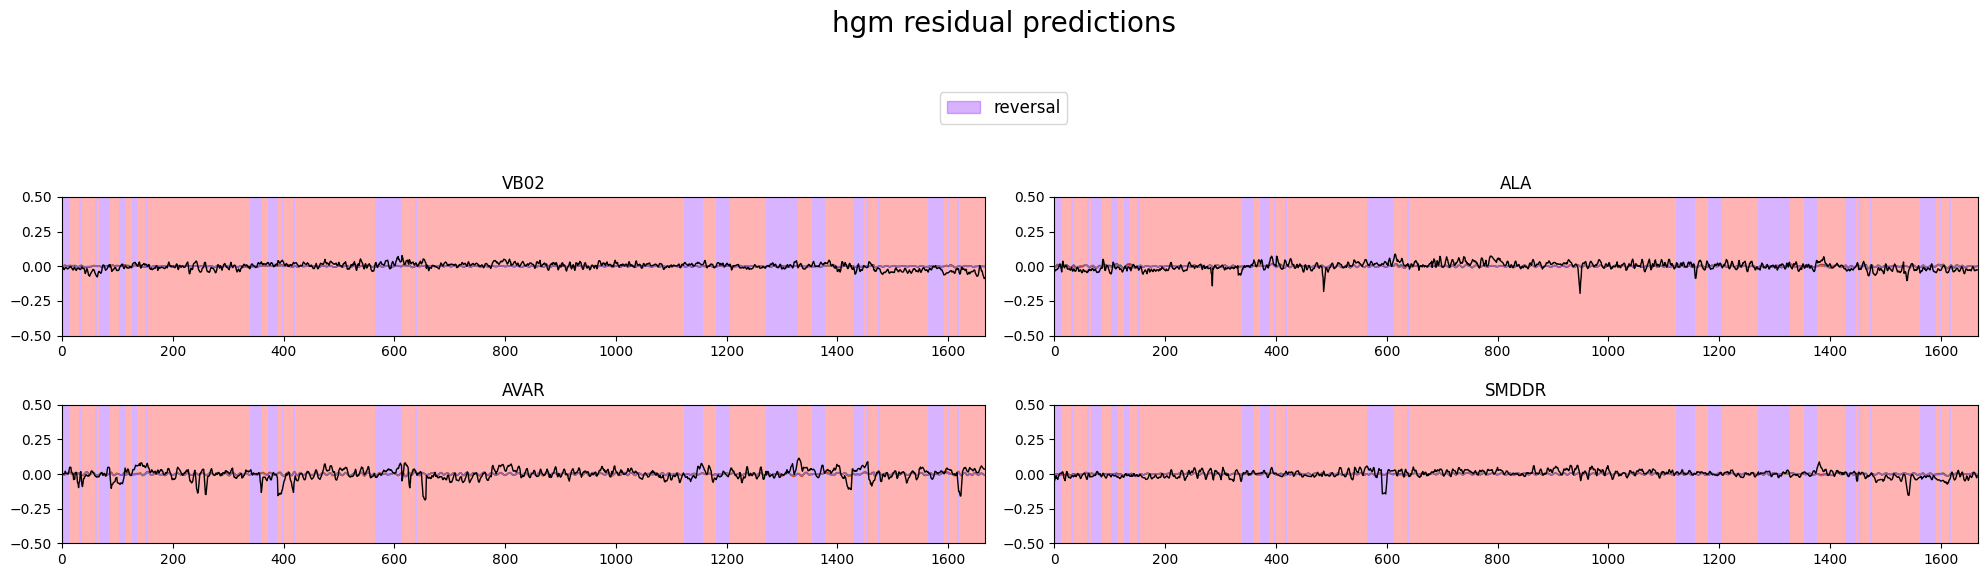

In [171]:
n_selection = ['VB02', 'ALA', 'AVAR', 'SMDDR']

alr_predicted_traces = [[pd.DataFrame(data=model.predict(eigenworms_gfp[i].values), columns=traces_gfp[i].columns) for model in alr_models_models_gfp[i]] for i in range(len(traces_gfp))]
plot_utils.plot_traces(traces_residual_gfp[worm_id][n_selection], discrete_states_gfp[worm_id]['REV'], 'alr residual predictions', alr_predicted_traces[worm_id], ylimits=(-0.5, 0.5))

clm_predicted_traces = [[pd.DataFrame(data=clm.predict(eigenworms_gfp[i].values, params['W']), columns=traces_gfp[i].columns) for params in clm_models_params_gfp[i]] for i in range(len(traces_gfp))]
plot_utils.plot_traces(traces_residual_gfp[worm_id][n_selection], discrete_states_gfp[worm_id]['REV'], 'clm residual predictions', clm_predicted_traces[worm_id], ylimits=(-0.5, 0.5))

hgm_predicted_traces = [[pd.DataFrame(data=hgm.predict(eigenworms_gfp[i].values, modes_manifold_gfp[i].values, params['W1'], params['W2']), columns=traces_gfp[i].columns) for params in hgm_models_params_gfp[i]] for i in range(len(traces_gfp))]
plot_utils.plot_traces(traces_residual_gfp[worm_id][n_selection], discrete_states_gfp[worm_id]['REV'], 'hgm residual predictions', hgm_predicted_traces[worm_id], ylimits=(-0.5, 0.5))

# assemble

In [172]:
neuron_scores_gcamp = assemble(filenames_gcamp, traces_gcamp, clm_models_scores_gcamp, hgm_models_scores_gcamp)
neuron_scores_gfp = assemble(filenames_gfp, traces_gfp, clm_models_scores_gfp, hgm_models_scores_gfp)

# Plot

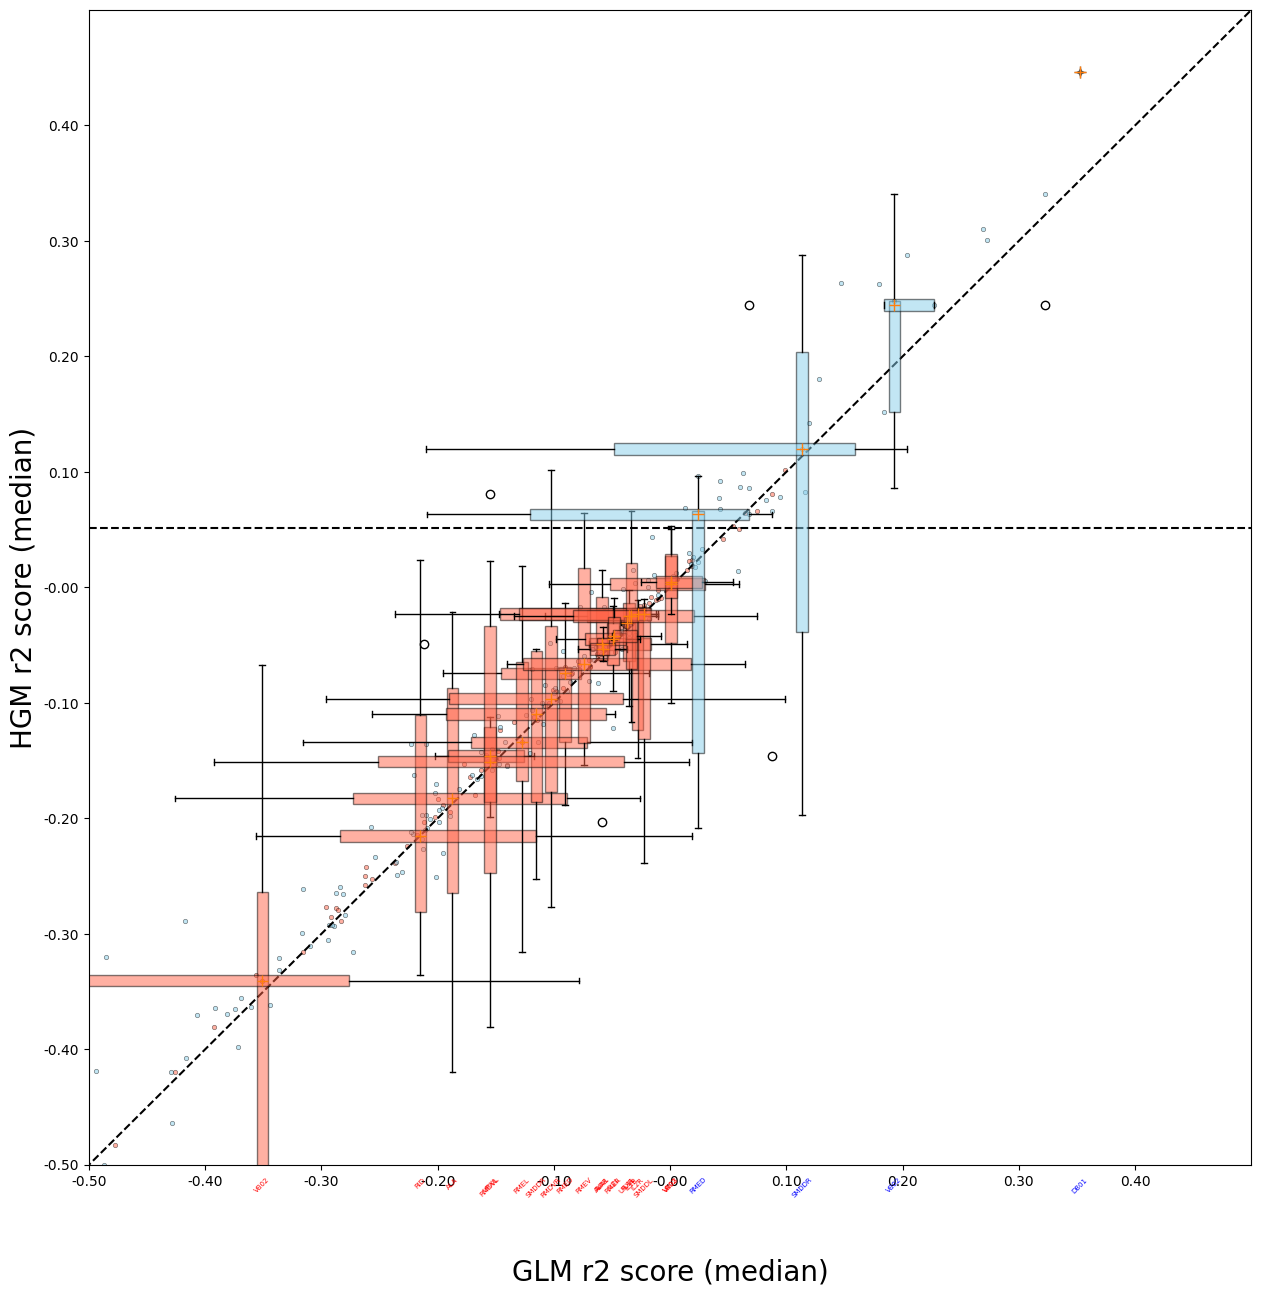

In [180]:
plot_utils.plot_performance_plot(neuron_scores_gcamp, neuron_scores_gfp, (-0.5, 0.5, -0.5, 0.5), save=True)

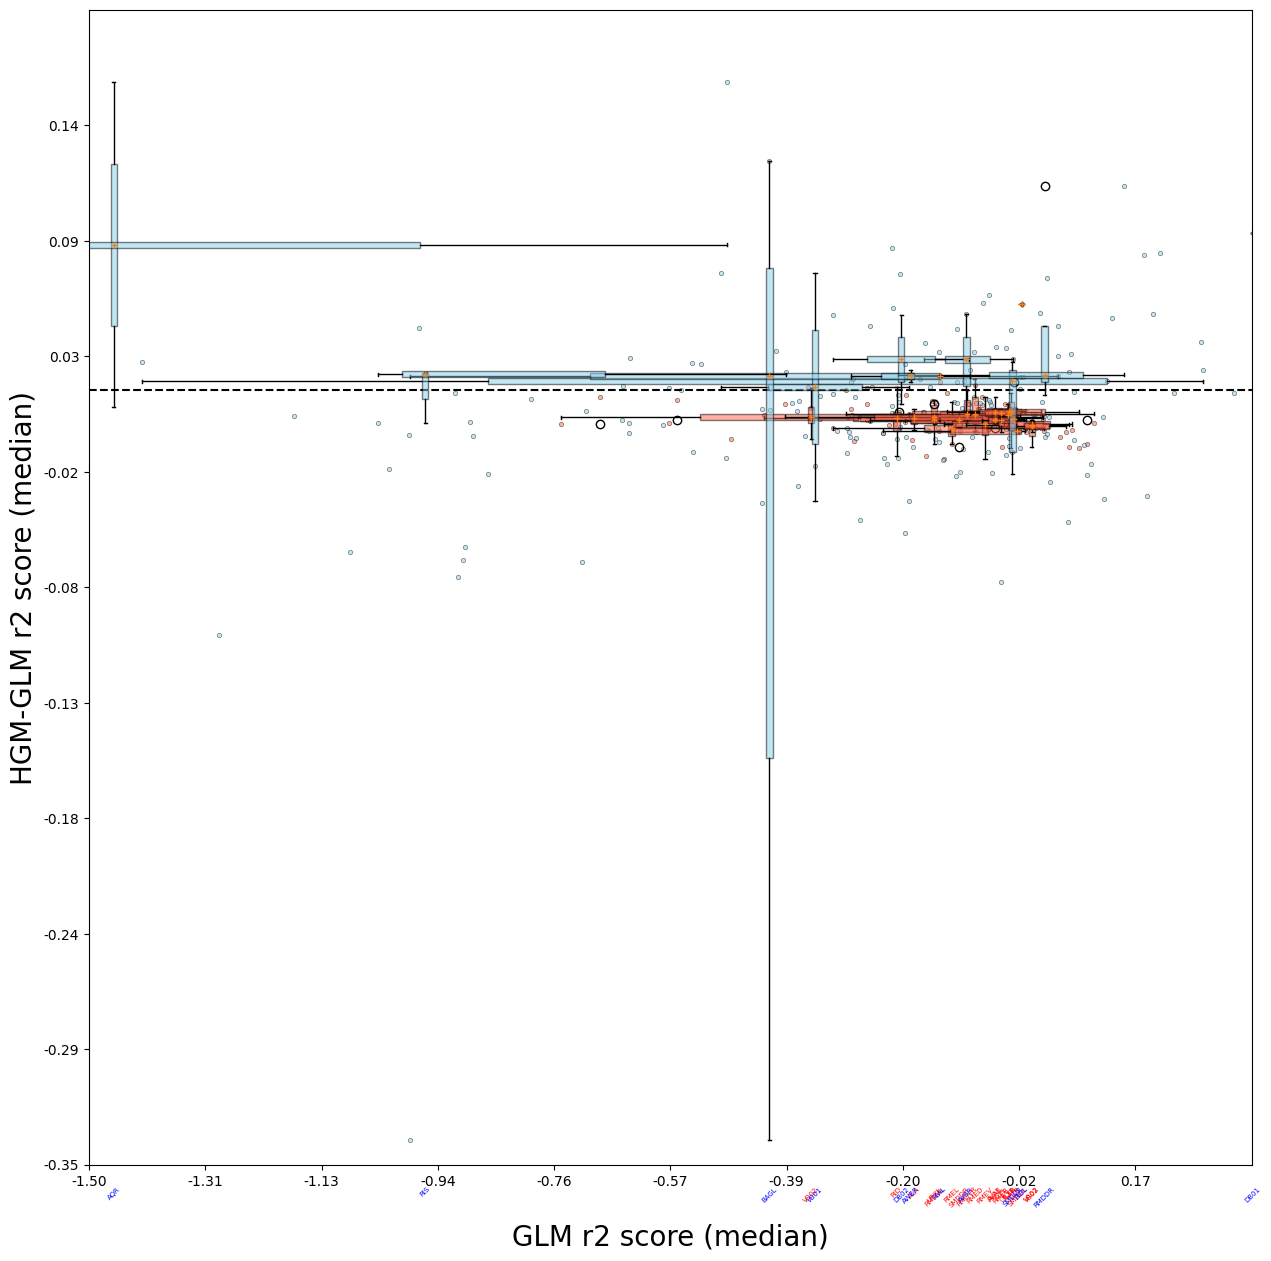

In [187]:
plot_utils.plot_improvement_plot(neuron_scores_gcamp, neuron_scores_gfp, (-1.5, 0.35, -0.35, 0.2), save=True)(-0.4, 0.2, -0.2, 0.2)